# SOM2.0: seismic facies from foundation-model embeddings, calibrated to wells

This notebook compares two unsupervised seismic-facies workflows. They share the same seismic volume, analysis
zone, self-organising map (SOM) and well calibration. **Only the features fed to the SOM differ.**

| | **SOM1.0** (multi-attribute) | **SOM2.0** (embedding) |
|---|---|---|
| Input features | ~33 attributes in 7 families (instantaneous, amplitude, spectral, similarity, dip, curvature, texture), computed from the seismic | 768-channel embedding from the NCS seismic foundation model ([NorskRegnesentral/NCS_models](https://github.com/NorskRegnesentral/NCS_models)) |
| Input selection | noisy attributes screened out by trace-to-trace continuity, then a PCA-guided choice of **distinct** attributes (no two with \|r\| ≥ 0.8) until they reconstruct 90 % of all-attribute variance; z-scored attribute values go to the SOM | PCs of the 2.5D embedding capturing 70 % of its variance, **whitened** (each PC scaled to unit variance, the analogue of z-scoring attributes) |
| Classification | 8 × 8 SOM (Kohonen map), batch algorithm | identical |
| Calibration | SOM nodes → well facies: biggest winner, and probabilistic (neighbour-smoothed) | identical |
| Scoring | leave-one-well-out at the well trace | identical |
| Deliverable | facies, confidence and P(oil sand) volumes (SEG-Y) | identical |

**The idea in one sentence:** a seismic attribute describes one trace over a few samples. An embedding from a model
pre-trained on thousands of seismic surveys describes each location *in the context of its surroundings*:
reflector continuity, terminations, texture and stacking pattern. Similar geology lands close together in the
embedding space, which is exactly what a SOM needs.

**How to read this notebook:** every step ends with one or more figures and a short *How to read it* note. Run
the cells top to bottom. Section 1 holds every path and setting.

## 1 · Configuration

In [1]:
from pathlib import Path

DATA = Path(r"C:\Data\Test")                                    # local data root (nothing is uploaded)
SEISMIC = DATA / "SEGY" / "1988_AVO18.sgy"                       # base seismic volume used by both workflows
NCS_FEATURES = DATA / "SEGY" / "1988_AVO18_ncs_25d_dir0_dens4_ov12.zarr-20261118T115803Z-1-001" / "1988_AVO18_ncs_25d_dir0_dens4_ov12.zarr"
                                 # NCS 2.5D embedding of the same volume (densify 4, crop overlap 12); a .zip works too
LAS_DIR = DATA / "LAS" / "MORE"                                  # well facies logs in TWT (one LAS per well)
PLOT_WELLS = ["App. 4", "Echo 1", "Echo 3", "Echo 2"]             # wells drawn on the strike line and maps
VERTICAL_WELLS = ["Echo 1", "Echo 2", "Echo 3", "App. 3", "App. 4"]  # only vertical wells are used: the tie places each
                                                                 # well on one trace, from the LAS X/Y
FACIES_CURVE = "elastic_lithofluid_facies_upscaled"              # seismic-scale facies curve used for scoring
RAW_FACIES_CURVE = "elastic_lithofluid_facies"                   # raw curve, shown for context only
TOP_HORIZON = DATA / "Horizons" / "Balder.txt"                   # analysis zone: top ...
BASE_HORIZON = DATA / "Horizons" / "MAURT.txt"                   # ... and base
FACIES_NAMES = {1: "Brine sand", 2: "Soft shale", 3: "Shale", 4: "Oil sand", 7: "Tuff", 8: "Overburden",
                10: "Carbonaceous"}
FACIES_COLOURS = {1: "#f2d03b", 2: "#9a8c6a", 3: "#7a7a7a", 4: "#2e9e47", 7: "#b07cc6", 8: "#3d3d3d",
                  10: "#c2410c"}
SOM_SHAPE = (8, 8)               # neurons, on a hexagonal map (6 neighbours each)
MAP_HORIZON = DATA / "Horizons" / "REST.txt"                      # top reservoir: maps are extracted along it ...
MAP_OFFSET_MS = 8                # ... this far below it (the pick is not perfect)
MAP_WINDOW_MS = 20               # P(oil sand) maps average this window below the horizon
SECTIONS = [("inline", 12362), ("crossline", 1553)]   # straight sections for the well-match figures
WELL_PROJECTION_TRACES = 35      # wells within this many traces of a section are projected onto it
ATTR_CONTINUITY_MIN = 0.8        # SOM1.0: drop attributes whose neighbour-trace correlation is below this
ATTR_R_MAX = 0.8                 # SOM1.0: no two selected attributes correlated |r| >= this
ATTR_VAR_TARGET = 0.90           # SOM1.0: add distinct attributes until they reconstruct this share of all-attribute variance
NCS_PC_VAR = 0.70                # SOM2.0: embedding variance captured by the PCs fed to the SOM
NCS_WHITEN = True                # SOM2.0: scale each PC to unit variance (equal weight, like z-scored attributes)
OUTPUT_DIR = DATA / "SEGY" / "som_outputs"                        # facies / confidence / P(oil sand) volumes
CAL_RADIUS = 1                   # calibration uses the (2r+1)^2 traces around each well; scoring uses the well trace
SEED = 0

In [2]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xarray as xr
sys.path.insert(0, str(Path.cwd()))
import som2, som2_plots as sp
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})
np.random.seed(SEED)

## 2 · Seismic and analysis zone
Both workflows use the same seismic volume and the same zone: the samples between the top and base horizons.

In [3]:
with som2.timer("load seismic"):
    cube, ilines, xlines, twt = som2.load_segy(SEISMIC)
dt_ms = float(np.median(np.diff(twt)))
to_ilxl, resid = som2.survey_affine(SEISMIC)
top = som2.load_horizon(TOP_HORIZON, ilines, xlines, to_ilxl)
base = som2.load_horizon(BASE_HORIZON, ilines, xlines, to_ilxl)
mask = som2.zone_from_horizons(top, base, twt)
zone_index = np.full(mask.shape, -1, np.int64); zone_index[mask] = np.arange(int(mask.sum()))
print(f"seismic {cube.shape} (inline x xline x samples), dt {dt_ms:g} ms, {twt[0]:.0f}-{twt[-1]:.0f} ms")
print(f"zone: {int(mask.sum()):,} samples; thickness {np.percentile(base - top, 5):.0f}-{np.percentile(base - top, 95):.0f} ms (P5-P95)")
print(f"inline/xline <-> X/Y affine fit residual {resid:.2f} m")

[load seismic] ...


[load seismic] 4.8s


seismic (401, 401, 251) (inline x xline x samples), dt 4 ms, 1812-2812 ms
zone: 9,792,539 samples; thickness 203-289 ms (P5-P95)
inline/xline <-> X/Y affine fit residual 0.40 m


## 3 · Well tie
Well locations come from the LAS header (X/Y), mapped to inline/crossline with an affine fit to the SEG-Y trace
headers. Each well is placed on a single trace, so **only vertical wells are used** (`VERTICAL_WELLS`). A deviated
well's facies would land on the wrong trace. This makes the result sensitive to the well ties: a time or position
mis-tie moves labels onto the wrong seismic. The calibration footprint (the traces around each well) softens
lateral errors but not time shifts. The facies log, in TWT, is put on the seismic sample grid by majority vote
within ± half a seismic sample. Ties go to the log sample nearest the seismic time. Code 0 (unclassified) is
dropped.

**Which facies curve:** use the *upscaled* (seismic-scale) curve for calibration and scoring. A raw curve adds beds
of a few milliseconds, one or two seismic samples thick, that no seismic method can resolve. In tests they were
never predicted and only lowered the scores. Resampling the seismic to 1 ms to match a finer log adds no
resolution either, because the band-limited data carry the same frequencies at either rate.

In [4]:
las = sorted(LAS_DIR.glob("*.las"))
wells_raw, info = som2.well_facies_on_grid(las, FACIES_CURVE, to_ilxl, ilines, xlines, twt)
for w in info:
    w["used"] = w["inside_survey"] and w["well"] in VERTICAL_WELLS
    w["note"] = "used" if w["used"] else ("outside survey" if not w["inside_survey"] else "not used: deviated")
wells_raw = {n: v for n, v in wells_raw.items() if n in VERTICAL_WELLS}
display(pd.DataFrame(info))
codes = sorted({int(c) for (_, _, _, f) in wells_raw.values() for c in f})
code_to_k = {c: k for k, c in enumerate(codes)}
n_fac = len(codes)
fac_names = [FACIES_NAMES.get(c, str(c)) for c in codes]
fac_cmap = sp.facies_cmap(codes, FACIES_COLOURS)
wells = {}
for name, (il, xl, t, f) in wells_raw.items():
    keep = mask[il, xl, t]                                   # well samples inside the zone
    wells[name] = (il[keep], xl[keep], t[keep], np.array([code_to_k[int(c)] for c in f[keep]]))
counts = pd.DataFrame({n: pd.Series(w[3]).map(dict(enumerate(fac_names))).value_counts() for n, w in wells.items()})
counts = counts.reindex(fac_names).fillna(0).astype(int)                 # rows in facies-code order
majority = counts.sum(1).max() / counts.values.sum()
print(f"majority-class baseline (predict the most common facies everywhere): {majority:.0%}")
path, well_pos = sp.well_line({n: w for n, w in wells.items() if n in PLOT_WELLS}, len(ilines), len(xlines))
t0 = int(np.searchsorted(twt, top[path[:, 0], path[:, 1]].min() - 50))
t1 = int(np.searchsorted(twt, base[path[:, 0], path[:, 1]].max() + 50))
trange = (twt[t0], twt[t1 - 1])

,well,inline,xline,inside_survey,used,note
0,App. 3,12360.1,1529.5,True,True,used
1,App. 4,12345.2,1691.6,True,True,used
2,Echo 1,12393.6,1622.8,True,True,used
3,Echo 2,12576.2,1530.9,True,True,used
4,Echo 3,12459.0,1552.2,True,True,used
5,Echo 4 P,12477.2,1579.2,True,False,not used: deviated
6,Echo 5 P,12477.8,1578.5,True,False,not used: deviated
7,Echo 6 P,12477.4,1579.4,True,False,not used: deviated
8,Echo 7 P,12477.8,1578.8,True,False,not used: deviated
9,Echo 8 P,12477.7,1579.6,True,False,not used: deviated


majority-class baseline (predict the most common facies everywhere): 39%


### QC: where the data are

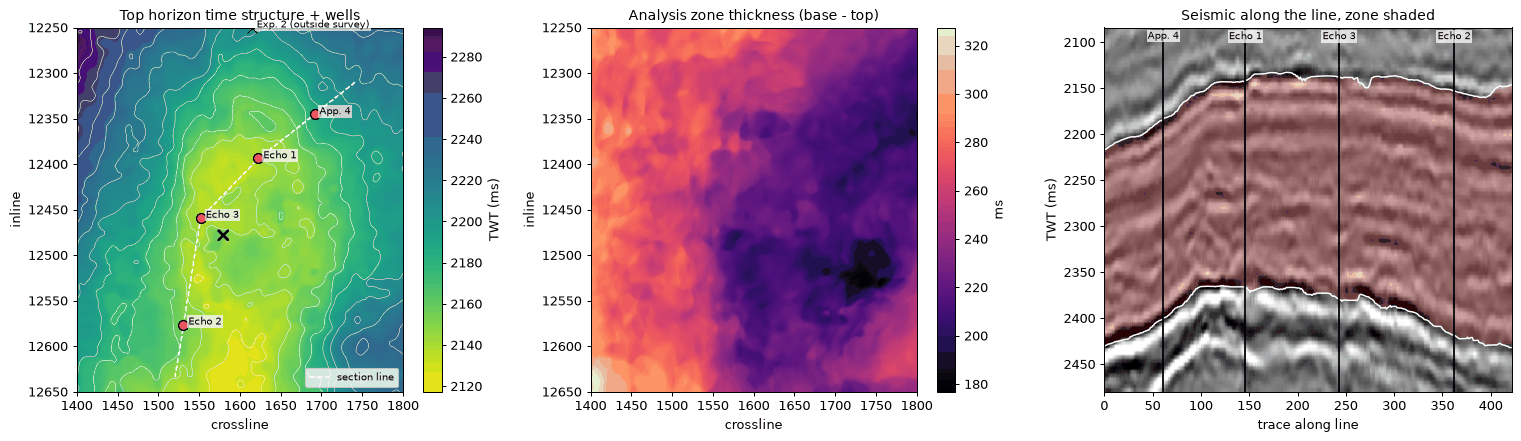

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ext = [xlines[0], xlines[-1], ilines[-1], ilines[0]]
im = ax[0].imshow(top, cmap="viridis_r", extent=ext, aspect="auto"); plt.colorbar(im, ax=ax[0], label="TWT (ms)")
ax[0].contour(xlines, ilines, top, levels=12, colors="w", linewidths=0.4)
ax[0].plot(xlines[path[:, 1]], ilines[path[:, 0]], "w--", lw=1.2, label="section line")
for w in [w for w in info if w["well"] in PLOT_WELLS or not w["used"]]:
    ax[0].plot(w["xline"], np.clip(w["inline"], ilines[0], ilines[-1]), "o" if w["used"] else "x",
               color="red" if w["used"] else "orange", ms=8, mec="k")
    if w["used"] or not w["inside_survey"]:
        lab = w["well"] if w["used"] else f"{w['well']} (outside survey)"
        ax[0].text(w["xline"] + 6, np.clip(w["inline"], ilines[0], ilines[-1]), lab, color="k", fontsize=8,
                   bbox=dict(fc="w", lw=0, alpha=0.7, pad=1))
ax[0].set(title="Top horizon time structure + wells", xlabel="crossline", ylabel="inline"); ax[0].legend(loc="lower right", fontsize=8)
im = ax[1].imshow(base - top, cmap="magma", extent=ext, aspect="auto"); plt.colorbar(im, ax=ax[1], label="ms")
ax[1].set(title="Analysis zone thickness (base - top)", xlabel="crossline", ylabel="inline")
sp.seismic_line(ax[2], cube, path, twt, t0, t1)
sp.overlay(ax[2], np.where(sp.zone_to_line(np.ones(int(mask.sum())), zone_index, path, t0, t1) > 0, 1.0, np.nan), path, twt, t0, t1,
           "autumn", alpha=0.18)
sp.decorate_line(ax[2], trange, well_pos, top, base, path); ax[2].set(title="Seismic along the line, zone shaded", xlabel="trace along line")
plt.tight_layout(); plt.show()

*How to read it:* left, the top-horizon time structure, with the wells and the section line used throughout.
Red circles are the vertical wells used. Wells marked × are deviated or outside the 3D, and aren't used. Middle, the zone thickness: every sample inside it is
classified. Right, the seismic along the line through the wells, with the zone shaded between the two horizons.

### QC: the facies logs

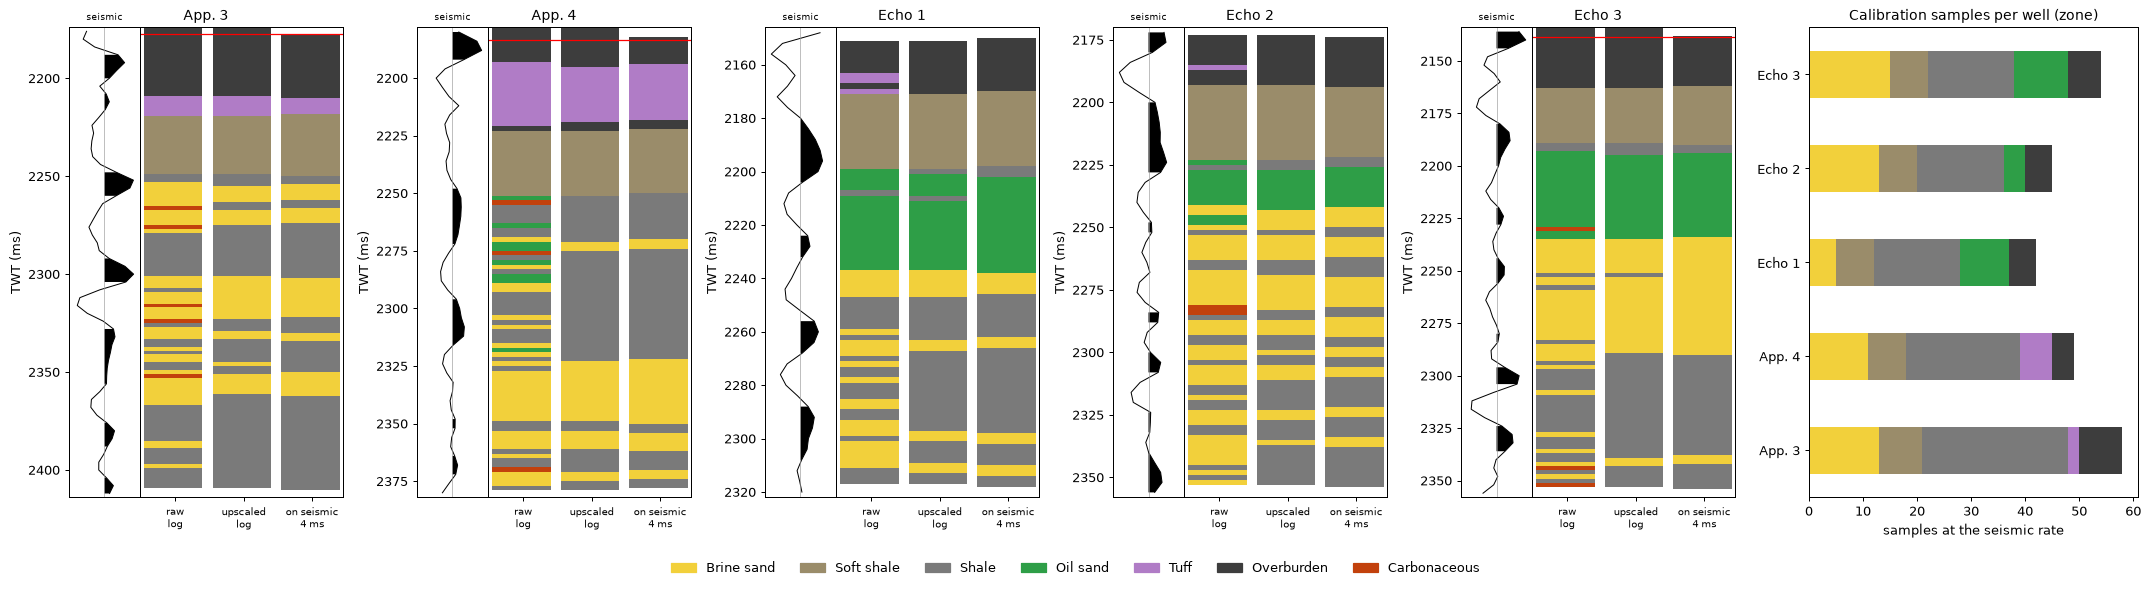

In [6]:
fig, axes = plt.subplots(1, len(wells) + 1, figsize=(4 * len(wells) + 4, 6.5), gridspec_kw={"width_ratios": [1] * len(wells) + [1.2]})
for ax, (name, (il, xl, t, f)) in zip(axes, wells.items()):
    hdr, c = som2.read_las(next(p for p in las if som2.read_las(p)[0].get("WELL") == name))
    lo, hi = twt[t].min() - 6, twt[t].max() + 6
    tr = c["DEPT"]; sel = (tr >= lo) & (tr <= hi)
    wax = ax.inset_axes([0.0, 0.0, 0.26, 1.0], transform=ax.transAxes)
    sp.wiggle_traces(wax, cube, il[0], xl[0], twt, lo, hi, half_width=0, sf=0.45)
    wax.set_xticks([]); wax.set_yticks([]); wax.set_title("seismic", fontsize=7)
    for j, (curve, dt) in enumerate([(RAW_FACIES_CURVE, 2.0), (FACIES_CURVE, 2.0)]):
        for tv, fv in zip(tr[sel], c[curve][sel]):
            if np.isfinite(fv) and fv > 0:
                ax.add_patch(plt.Rectangle((1.1 + j, tv - dt / 2), 0.85, dt, color=FACIES_COLOURS.get(int(fv), "#ccc"), lw=0))
    for tv, fv in zip(twt[t], f):
        ax.add_patch(plt.Rectangle((3.1, tv - dt_ms / 2), 0.85, dt_ms, color=fac_cmap(fv), lw=0))
    ax.axhline(top[il[0], xl[0]], color="r", lw=1); ax.axhline(base[il[0], xl[0]], color="r", lw=1)
    ax.set_xlim(0, 4); ax.set_ylim(hi, lo); ax.set_title(name)
    ax.set_xticks([1.55, 2.55, 3.55], ["raw\nlog", "upscaled\nlog", f"on seismic\n{dt_ms:g} ms"], fontsize=8)
    ax.set_ylabel("TWT (ms)")
counts.T.plot.barh(stacked=True, ax=axes[-1], color=[fac_cmap(i) for i in range(n_fac)], legend=False)
axes[-1].set(title="Calibration samples per well (zone)", xlabel="samples at the seismic rate")
all_codes = sorted(set(codes) | {7, 10})
sp.facies_legend(fig, [FACIES_NAMES[c] for c in all_codes], sp.facies_cmap(all_codes, FACIES_COLOURS), y=-0.01)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

*How to read it:* for each well, the seismic trace at the well location (variable-area wiggle), then the raw
facies log, the upscaled log, and the facies actually used, one per seismic sample. Red lines mark the zone top and base. Thin raw-log beds (tuff,
carbonaceous) disappear at seismic scale: they are real, but below seismic resolution. Right, how many calibration
samples each well contributes per facies. Small counts mean noisy per-facies scores.

## 4 · SOM1.0: multi-attribute workflow
A family-balanced library of the attributes commonly used in multi-attribute SOM studies, all computed from the
single base volume:
- **Instantaneous:** amplitude, quadrature, envelope, normalised amplitude, phase, envelope-weighted frequency,
  thin bed, Q, attenuation, bandwidth, envelope slope and second derivative.
- **Amplitude:** RMS, average energy, sweetness, relative acoustic impedance.
- **Spectral decomposition:** 15–60 Hz band magnitudes, peak frequency, peak magnitude.
- **Similarity:** coherence, coherent energy, Sobel.
- **Dip:** dip magnitude.
- **Curvature:** most positive, most negative, curvedness.
- **Texture:** GLCM-style entropy, contrast, homogeneity.

Banded attributes (averages between phase or envelope breaks picked trace by trace) are left out: they jump from
trace to trace and add vertical striping.

**Continuity screen first.** Each attribute is scored by how well it correlates with itself one trace away. Spiky
attributes (typically instantaneous Q and thin bed) fall below the threshold and are removed. Otherwise the
selection below would favour them, because noise is uncorrelated with everything.

**Selecting the SOM inputs without double counting.** Walk the principal components in order. From each, take the
attribute with the highest loading, unless it correlates |r| ≥ 0.8 with an attribute already chosen. Stop when the
chosen attributes reconstruct 90% of the variance of *all* attributes. The number of attributes falls out of the
data instead of being fixed, and near-duplicates (for example sweetness and its banded versions) can't all get in.
The SOM then runs on the selected attribute values, not on PC scores.

In [7]:
with som2.timer("SOM1.0 attributes"):
    lib_names, lib_fam, X = som2.som1_library(cube, dt_ms, mask)
continuity = som2.continuity_score(X, mask)
keep_attr = [i for i in range(len(lib_names)) if continuity[i] >= ATTR_CONTINUITY_MIN]
print("screened out (continuity):", [(lib_names[i], round(float(continuity[i]), 2)) for i in range(len(lib_names)) if i not in keep_attr])
X = X[:, keep_attr]
attr_names = [lib_names[i] for i in keep_attr]
attr_fam = [lib_fam[i] for i in keep_attr]
pca1 = som2.pca_fit(X)
sel_idx, sel_names, sel_r2 = som2.select_distinct(X, attr_names, ATTR_R_MAX, ATTR_VAR_TARGET, seed=SEED)
Z1 = ((X[:, sel_idx] - X[:, sel_idx].mean(0)) / (X[:, sel_idx].std(0) + 1e-9)).astype(np.float32)
pc1_rgb = sp.rgb_from_scores(som2.pca_transform(X, pca1, 3))          # for the colour-blend QC below
print(f"{len(lib_names)} attributes computed, {len(attr_names)} pass the screen; {len(sel_idx)} distinct attributes reconstruct {sel_r2[-1]:.0%} of their variance:")
print(sel_names)

[SOM1.0 attributes] ...


[SOM1.0 attributes] 143.1s


screened out (continuity): [('thin_bed', 0.6), ('inst_q', 0.13), ('sobel_similarity', 0.44)]


33 attributes computed, 30 pass the screen; 16 distinct attributes reconstruct 94% of their variance:
['rms_amplitude', 'relative_acoustic_impedance', 'glcm_contrast', 'bandwidth', 'dip_magnitude', 'normalized_amplitude', 'curvature_most_positive', 'curvature_most_negative', 'curvedness', 'envelope_slope', 'envelope_2nd_derivative', 'coherence', 'spec_15Hz', 'glcm_entropy', 'inst_phase_sin', 'peak_frequency']


### QC: how the attributes are picked

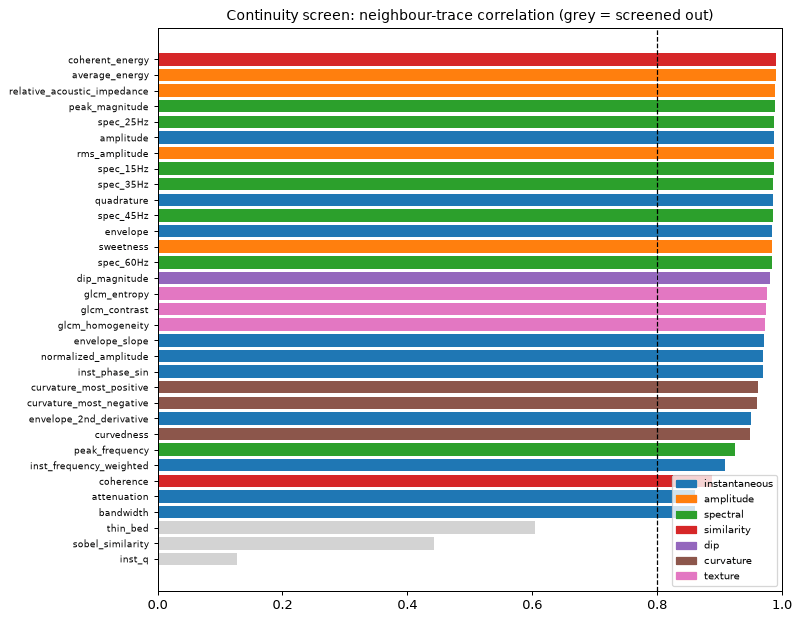

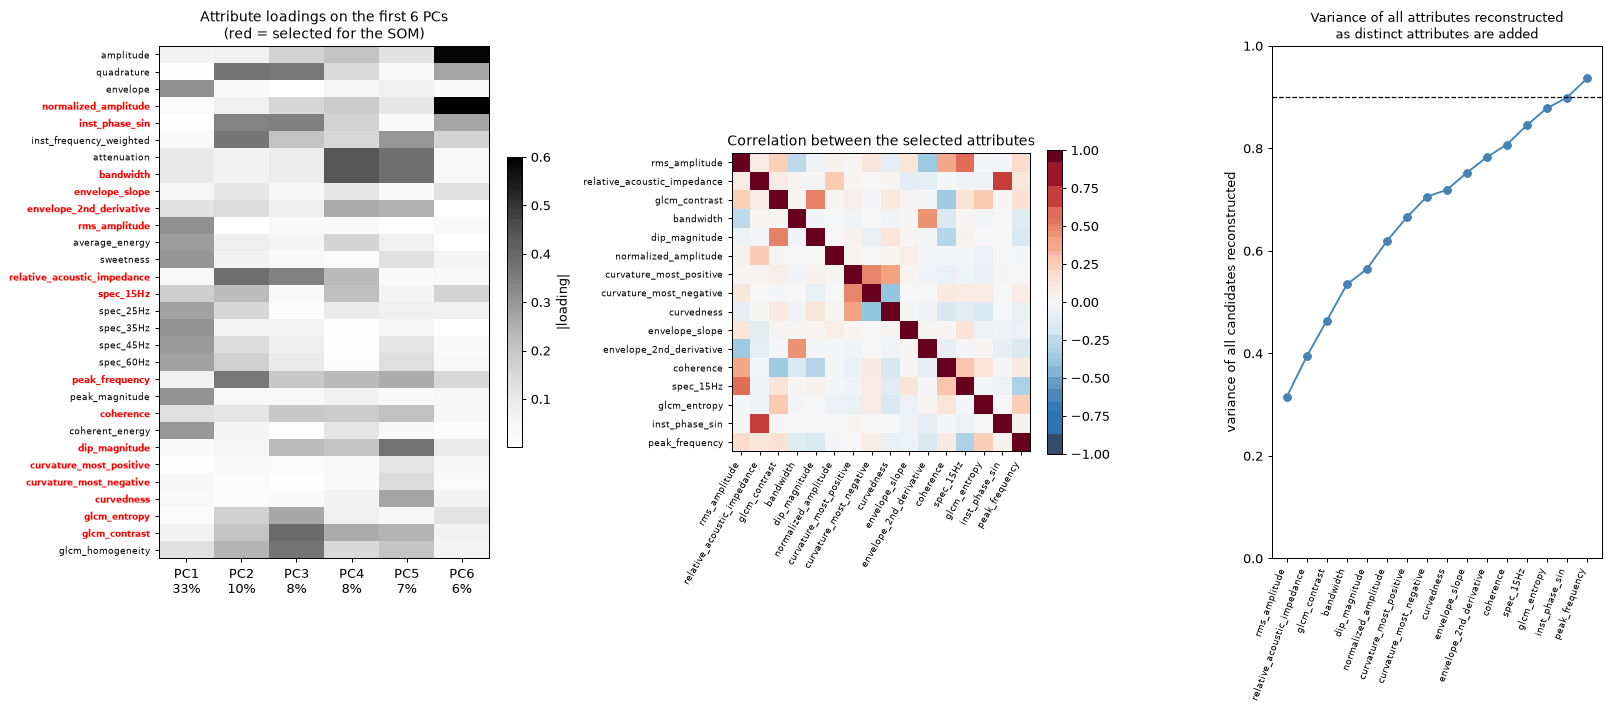

In [8]:
fam_cols = dict(zip(som2.SOM1_FAMILIES, plt.cm.tab10.colors))
o = np.argsort(continuity)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(range(len(o)), continuity[o], color=[fam_cols[lib_fam[i]] if continuity[i] >= ATTR_CONTINUITY_MIN else "lightgrey" for i in o])
ax.set_yticks(range(len(o)), [lib_names[i] for i in o], fontsize=7); ax.axvline(ATTR_CONTINUITY_MIN, color="k", ls="--", lw=1)
ax.set(xlim=(0, 1), title="Continuity screen: neighbour-trace correlation (grey = screened out)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_cols.values()], list(fam_cols), fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(18, 8), gridspec_kw={"width_ratios": [1.1, 1, 1]})
L = np.abs(pca1["comps"][:6]).T
im = ax[0].imshow(L, cmap="Greys", aspect="auto"); plt.colorbar(im, ax=ax[0], fraction=0.04, label="|loading|")
ax[0].set_yticks(range(len(attr_names)), attr_names, fontsize=7)
for i in sel_idx:
    ax[0].get_yticklabels()[i].set_color("red"); ax[0].get_yticklabels()[i].set_fontweight("bold")
ax[0].set_xticks(range(6), [f"PC{i+1}\n{v:.0%}" for i, v in enumerate(pca1["var_ratio"][:6])])
ax[0].set_title("Attribute loadings on the first 6 PCs\n(red = selected for the SOM)")
corr = np.corrcoef(Z1[np.random.default_rng(0).choice(len(Z1), 200_000, replace=False)].T)
im = ax[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); plt.colorbar(im, ax=ax[1], fraction=0.046)
ax[1].set_xticks(range(len(sel_names)), sel_names, rotation=60, ha="right", fontsize=7)
ax[1].set_yticks(range(len(sel_names)), sel_names, fontsize=7); ax[1].set_title("Correlation between the selected attributes")
sp.selection_curve(ax[2], sel_names, sel_r2, ATTR_VAR_TARGET, "Variance of all attributes reconstructed\nas distinct attributes are added")
plt.tight_layout(); plt.show()

*How to read it:* first, every library attribute's continuity, coloured by family; grey ones are removed before
selection. Then, left, each row is an attribute and each column a principal component. Dark means the attribute
drives that component. The red attributes are the ones PCA selection keeps. Middle, how strongly the selected
attributes correlate with each other. With the distinct rule, no off-diagonal cell reaches ±0.8, so no
attribute is counted twice. Right, how much of the variance of all attributes the selection reconstructs as each
attribute is added, stopping at the dashed target.

### QC: the selected attributes on the section

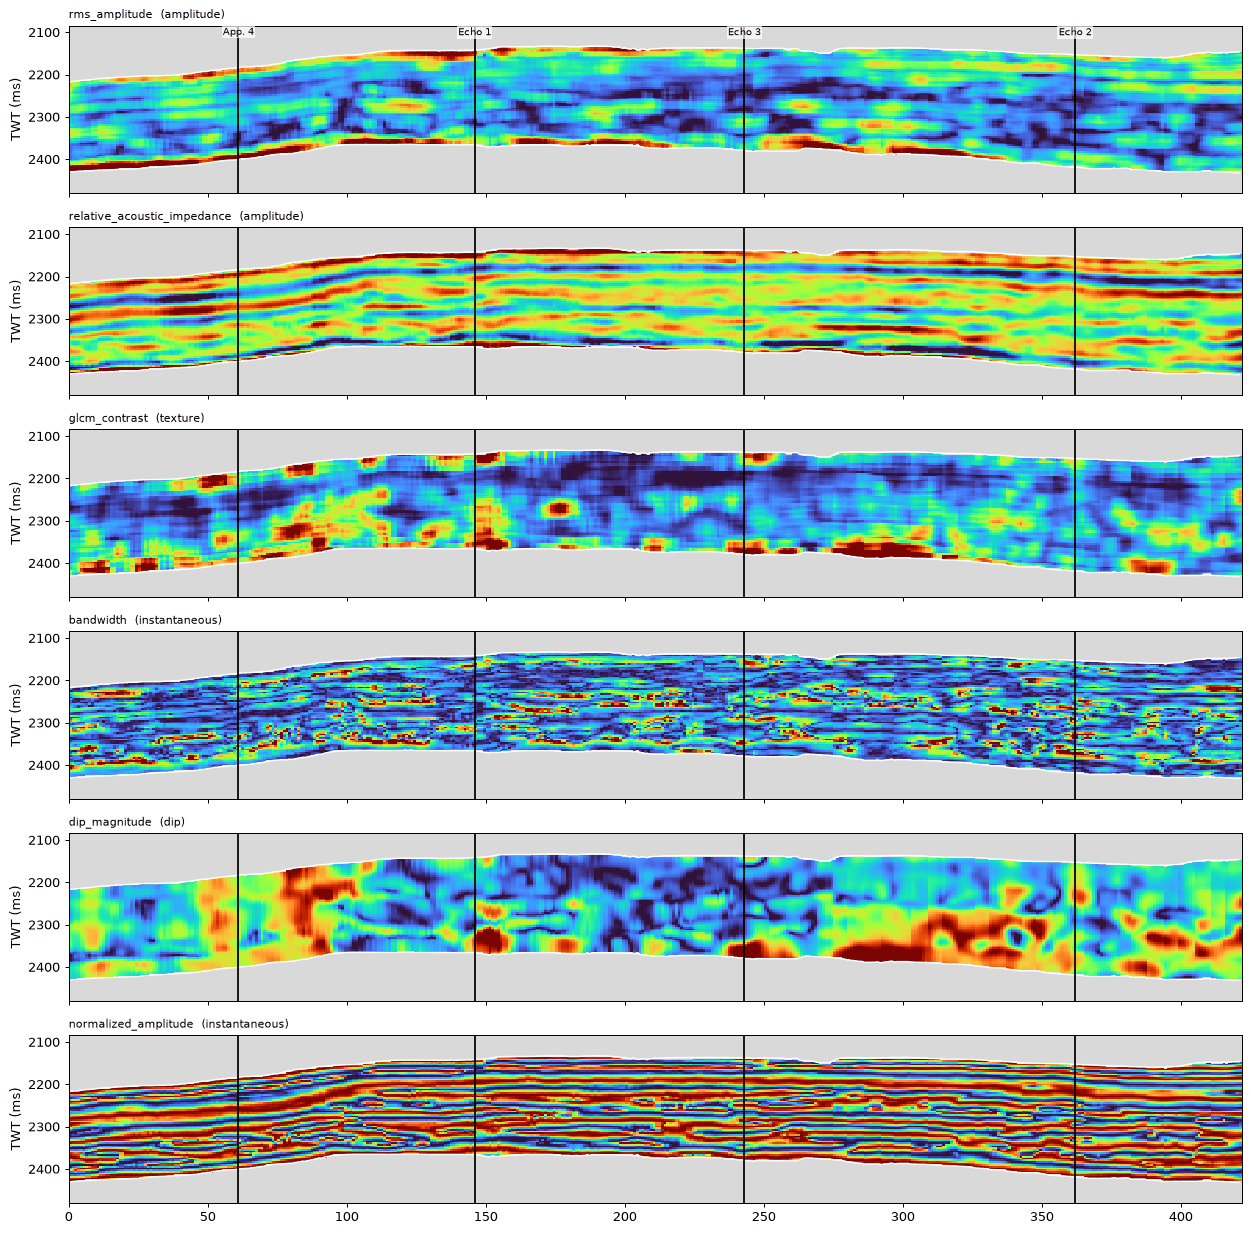

In [9]:
show = sel_idx[:6]
fig, axes = plt.subplots(len(show), 1, figsize=(14, 2.3 * len(show)), sharex=True)
for ax, i in zip(axes, show):
    img = sp.zone_to_line(X[:, i], zone_index, path, t0, t1)
    lo, hi = np.nanpercentile(img, [2, 98])
    ax.set_facecolor("0.85")
    sp.overlay(ax, img, path, twt, t0, t1, "turbo", lo, hi, alpha=1.0)
    sp.decorate_line(ax, trange, well_pos, top, base, path, label=(i == show[0])); ax.set_title(f"{attr_names[i]}  ({attr_fam[i]})", fontsize=9, loc="left")
plt.tight_layout(); plt.show()
del X

*How to read it:* the first six attributes that go into the SOM, with their family, shown on their own (no
seismic underneath) inside the zone, along the strike line through the wells. Attributes are computed on the whole
trace and only then sampled in the zone, so there are no edge effects at the horizons.

[SOM1.0 SOM] ...


[SOM1.0 SOM] 3.9s


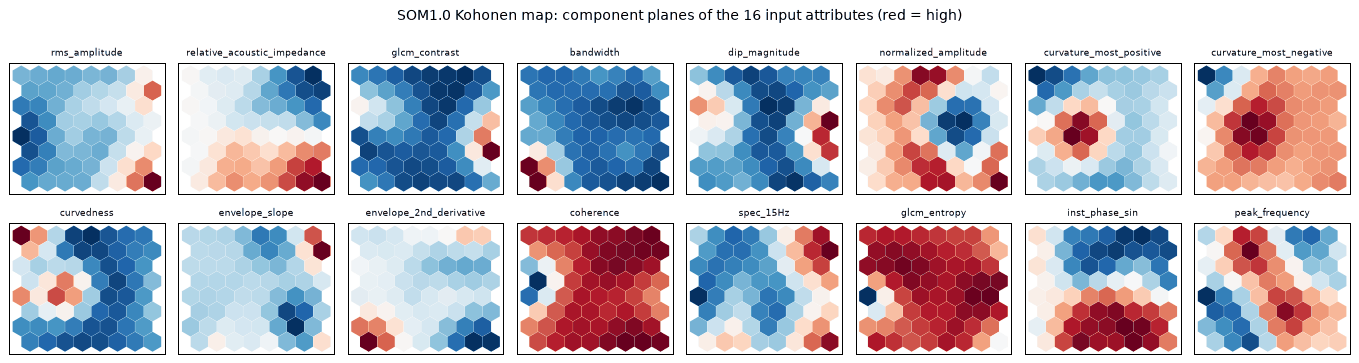

In [10]:
with som2.timer("SOM1.0 SOM"):
    W1, snaps1 = som2.train_som(Z1, SOM_SHAPE, seed=SEED)
    b1 = som2.bmu(Z1, W1)
fig = sp.component_planes(W1, sel_names, SOM_SHAPE, f"SOM1.0 Kohonen map: component planes of the {len(sel_names)} input attributes (red = high)",
                          max_n=len(sel_names))
plt.show()

*How to read it:* each small map is the trained 8 × 8 Kohonen map coloured by one input attribute. Neurons in the
same position on every plane are the same neuron. Attributes whose planes look alike vary together across the
map; a plane with its own distinct pattern carries its own information. Where several planes are extreme together
(the same corner red in several maps), that group of neurons represents seismic with that combination of
character.

## 5 · SOM2.0: foundation-model embedding
The embedding comes from the NCS model: a ViT encoder with masked-autoencoder pre-training on public Norwegian
Continental Shelf seismic. We use the **2.5D** model. It runs the encoder along four vertical directions (inline,
crossline and the two diagonals) and combines them, so each vector also reflects the geology across the section.
The 2D model processes sections independently. To create the embedding for a new volume:

```python
som2.run_ncs(SEISMIC, "features.zarr", model="NorskRegnesentralSTI/NCS-v1-2.5d-base", densify=4,
             num_overlap_patches=12)   # GPU recommended: ~3 minutes for this volume on a Colab GPU
```

**Normalisation.** Two steps, both standard for this model:
- **Input seismic:** before inference, the NCS pipeline scales the cube to unit variance and clips amplitudes
  beyond ±3 standard deviations (inference defaults `normalization_mode="std"`, `clip_sigma=3`). That is the same
  normalisation the model's pre-training data received, so absolute amplitude levels don't matter.
- **Embedding:** each of the 768 channels is z-scored (mean 0, standard deviation 1, over the whole feature cube)
  before PCA, as in the NCS paper's own evaluations. No channel dominates just because of its scale.

The NCS models were pre-trained on **full-stack** cubes. Here they're applied to a **mid-angle stack** (AVO18). After
the normalisation above, the main differences are relative amplitudes between interfaces (the AVO response at that
angle range) and somewhat lower signal-to-noise, both well within the variability of the 829 training cubes.

**Registration:** the store's `inline/xline/time_depth` coordinates are 0-based sample indices of the input
volume, at the patch start + `patch_size // 2`. The true patch centre is therefore half a sample earlier. The
features are interpolated from that grid onto the seismic samples of the zone.

**Why PCs, and how many.** Individual embedding channels aren't meaningful the way attributes are: the information
is spread across combinations of channels. So the SOM gets principal components, which are uncorrelated by
construction (no double counting). The embedding spreads its variance widely: 8 PCs capture under 20%, 70% needs
roughly 90 PCs, and 90% needs over 200. We use the PCs that capture 70%.

**Whitening.** PC scores have very different variances: PC1 is large, PC80 tiny. Fed to the SOM as they are,
the first few PCs dominate every distance and the rest barely count. Scaling each PC to unit variance gives them
equal weight. That's the same treatment SOM1.0's attributes get from z-scoring, so the comparison is fair. In
tests, whitening was the single biggest improvement to SOM2.0.

**Crop overlap.** Inference tiles the volume into overlapping 224 × 224 crops. With the default overlap (a crop
every 112 traces), some channels encode position within the crop and repeat with that spacing. Overlap 12 (a
crop every 32 traces) blends each point from about 7 crops, which averages this out. The tiling check below
measures what remains.

In [11]:
ds = som2.open_ncs(NCS_FEATURES)
F = ds["features"]
gi = som2._coord_to_index(ds["inline"].values, ilines.astype(float))
gx = som2._coord_to_index(ds["xline"].values, xlines.astype(float))
gt = som2._coord_to_index(ds["time_depth"].values, twt)
fi = np.abs(gi[None] - path[:, :1]).argmin(1); fx = np.abs(gx[None] - path[:, 1:]).argmin(1)
ft = np.abs(gt[None] - np.arange(t0, t1)[:, None]).argmin(1)
with som2.timer("read embedding along line"):
    E = F.isel(inline=xr.DataArray(fi), xline=xr.DataArray(fx)).values            # (trace, feature-time, 768)
E = E[:, ft]                                                                       # nearest feature sample per seismic sample
En = E / (np.linalg.norm(E, axis=-1, keepdims=True) + 1e-9)
ref_w = max(wells, key=lambda w: (wells[w][3] == code_to_k.get(4, -1)).sum())     # well with the most oil sand
ref_t = int(np.median(wells[ref_w][2][wells[ref_w][3] == code_to_k.get(4, 0)])) - t0
ref = En[well_pos[ref_w], ref_t]
print(f"embedding grid {dict(F.sizes)}; reference point: {ref_w} at {twt[ref_t + t0]:.0f} ms")

NCS group: dir0 {'inline': 101, 'xline': 101, 'time_depth': 63, 'feature': 768}
[read embedding along line] ...


[read embedding along line] 2.9s


embedding grid {'inline': 101, 'xline': 101, 'time_depth': 63, 'feature': 768}; reference point: Echo 3 at 2212 ms


[SOM2.0] ...


[ncs_load] ...


[ncs_load] 3.8s


[ncs_pca] ...


[ncs_pca] 9.7s


[ncs_interp_to_seismic] ...


[ncs_interp_to_seismic] 18.7s


[SOM2.0] 43.5s


SOM2.0 input: 85 PCs = 70% of embedding variance, whitened


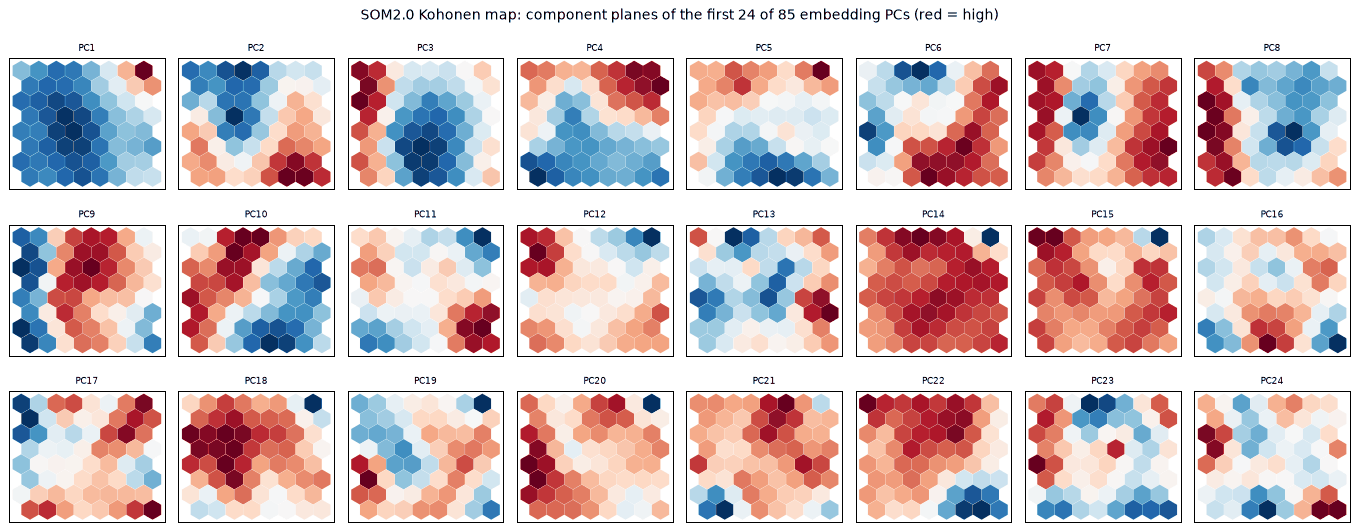

In [12]:
with som2.timer("SOM2.0"):
    pca2, k2, Z2 = som2.ncs_pcs_on_zone(ds, mask, ilines, xlines, twt, NCS_PC_VAR)
    if NCS_WHITEN:
        Z2 = Z2 / (Z2.std(0) + 1e-9)
    W2, snaps2 = som2.train_som(Z2, SOM_SHAPE, seed=SEED)
    b2 = som2.bmu(Z2, W2)
rgb2 = sp.rgb_from_scores(Z2)
NAME2 = f"SOM2.0 ({k2} PCs)"
print(f"SOM2.0 input: {k2} PCs = {pca2['var_ratio'][:k2].sum():.0%} of embedding variance, {'whitened' if NCS_WHITEN else 'raw scores'}")
fig = sp.component_planes(W2, [f"PC{i + 1}" for i in range(k2)], SOM_SHAPE,
                          f"SOM2.0 Kohonen map: component planes of the first 24 of {k2} embedding PCs (red = high)")
plt.show()
del Z2

*How to read it:* the same Kohonen component-plane view for SOM2.0, one map per embedding PC. The leading PCs
organise the map into broad smooth regions; later PCs add finer distinctions within them.

### QC: what the embedding sees

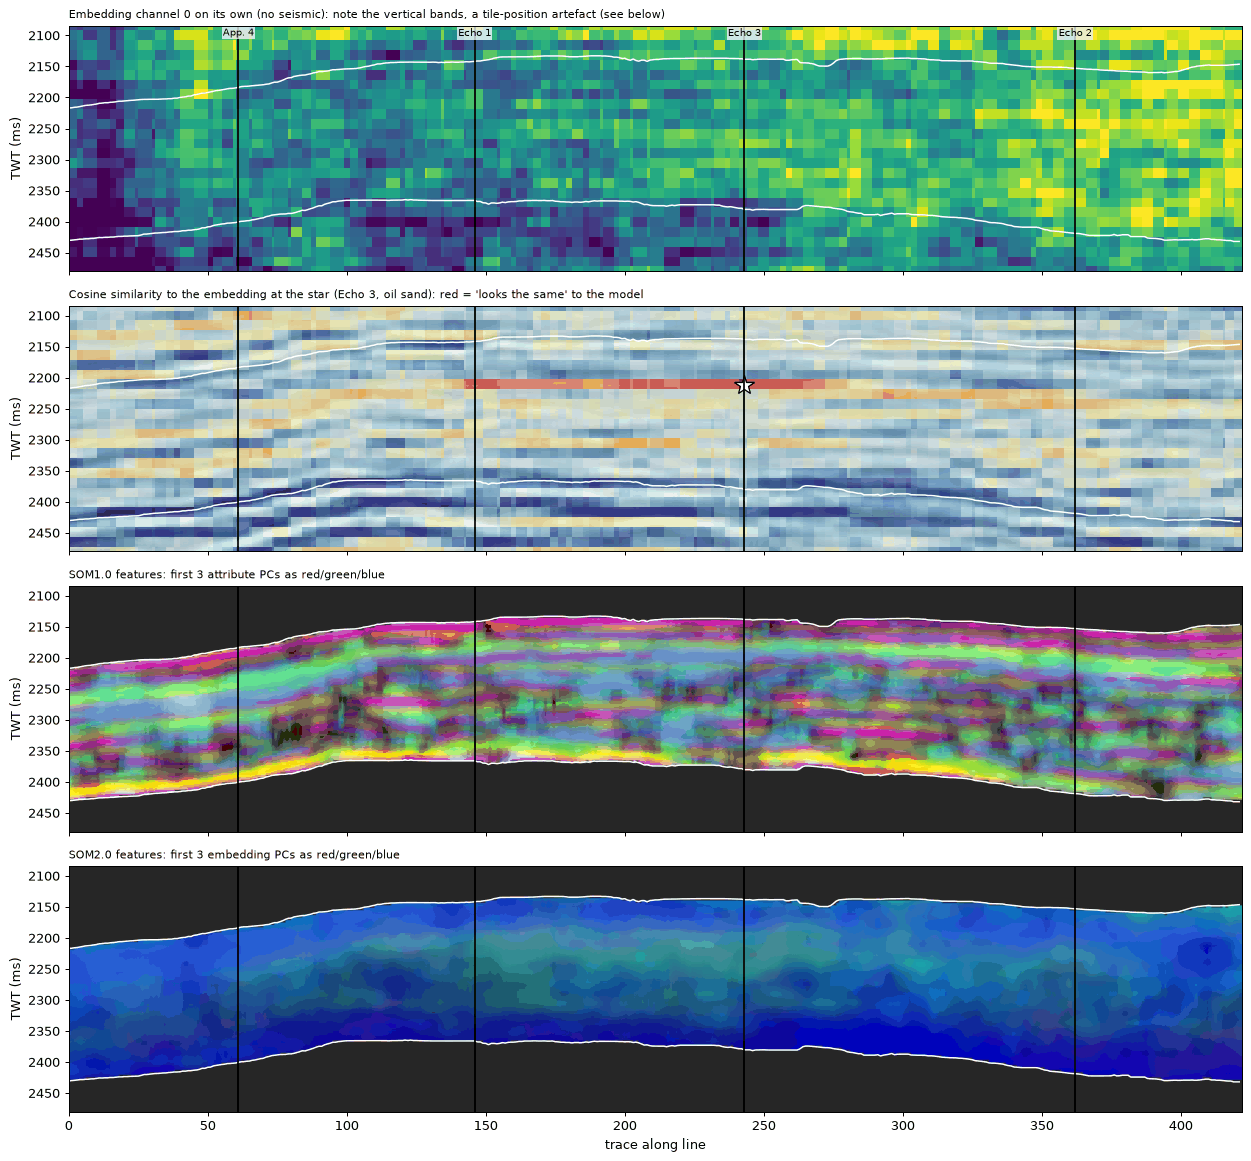

In [13]:
fig, ax = plt.subplots(4, 1, figsize=(14, 13), sharex=True)
ch = E[..., 0].T
sp.overlay(ax[0], ch, path, twt, t0, t1, "viridis", *np.percentile(ch, [2, 98]), alpha=1.0)
ax[0].set_title("Embedding channel 0 on its own (no seismic): note the vertical bands, a tile-position artefact (see below)", loc="left", fontsize=9)
sim = (En @ ref).T
sp.seismic_line(ax[1], cube, path, twt, t0, t1)
im = sp.overlay(ax[1], sim, path, twt, t0, t1, "RdYlBu_r", -0.2, 1.0, alpha=0.75)
ax[1].plot(well_pos[ref_w], twt[ref_t + t0], "w*", ms=16, mec="k")
ax[1].set_title(f"Cosine similarity to the embedding at the star ({ref_w}, oil sand): red = 'looks the same' to the model", loc="left", fontsize=9)
ax[2].imshow(sp.rgb_line(pc1_rgb, zone_index, path, t0, t1), aspect="auto", extent=[0, len(path), twt[t1 - 1], twt[t0]])
ax[2].set_title("SOM1.0 features: first 3 attribute PCs as red/green/blue", loc="left", fontsize=9)
ax[3].imshow(sp.rgb_line(rgb2, zone_index, path, t0, t1), aspect="auto", extent=[0, len(path), twt[t1 - 1], twt[t0]])
ax[3].set_title("SOM2.0 features: first 3 embedding PCs as red/green/blue", loc="left", fontsize=9)
for a in ax:
    sp.decorate_line(a, trange, well_pos, top, base, path, label=(a is ax[0]))
ax[-1].set_xlabel("trace along line"); plt.tight_layout(); plt.show()

*How to read it:*
- **Top:** embedding channel 0 on its own. Its vertical bands are not geology; see the tiling check below.
- **Second:** pick one point (the star, in oil sand) and colour every location by how similar its embedding is.
  The model groups the reservoir interval laterally without being told anything about it.
- **Bottom two:** the first three components of each workflow's features, shown as colours. Colour changes are
  what the SOM can separate. The attribute blend (SOM1.0) changes at the scale of individual wavelet loops. The
  embedding blend (SOM2.0) changes at the scale of geological units.

### QC: raw embedding channels and the tiling artefact
Inference tiles the volume into overlapping 224 × 224 crops. A ViT token carries information about where it sits
in its crop, so some channels repeat with the tile spacing. Below: 16 channels on the native feature grid with no
seismic and no interpolation, as an inline section and as a time slice. Then, for every channel and the leading
PCs, the share of variance explained purely by position within the tile along the crossline.

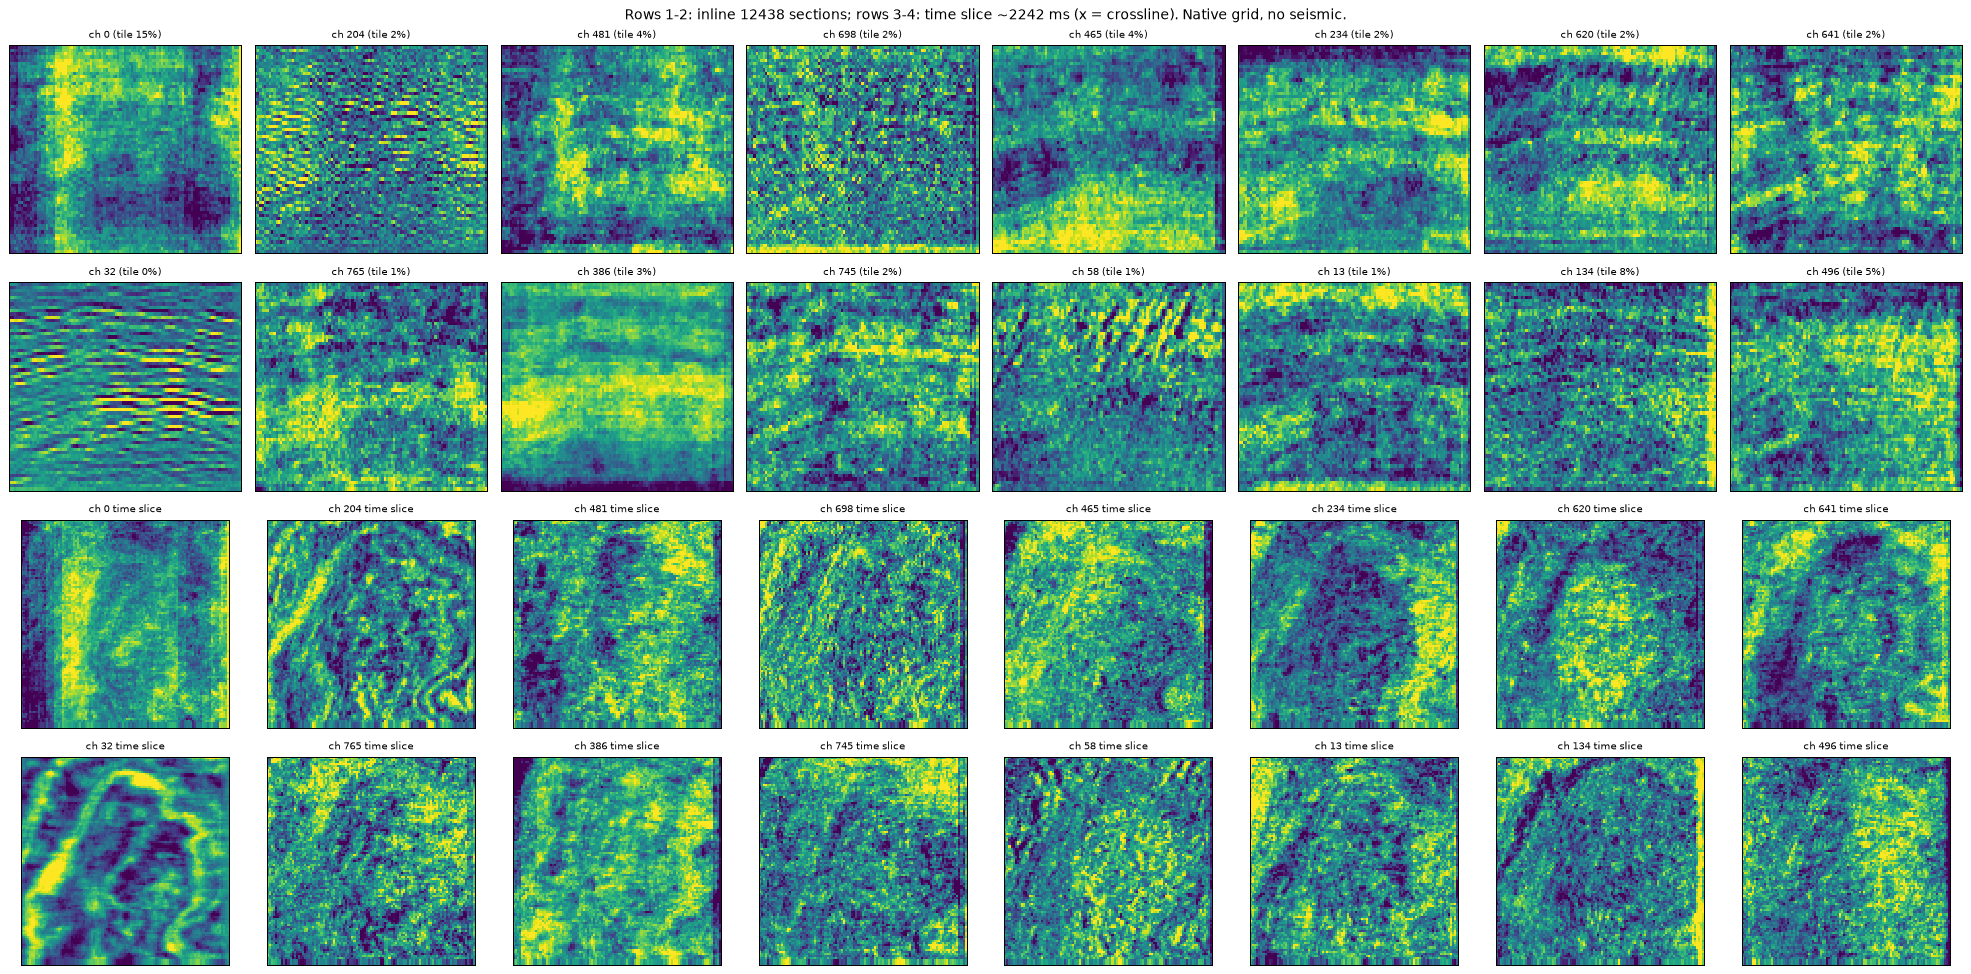

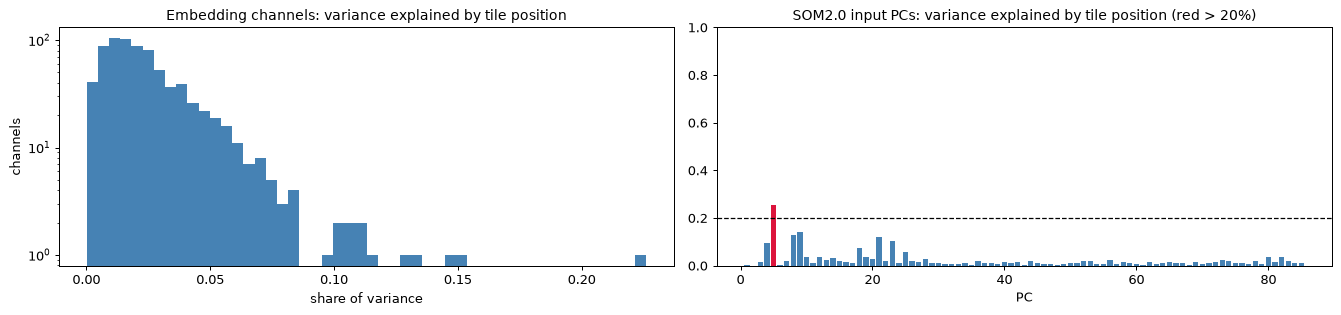

channels with >10% tile-position variance: 12 of 768; PCs >20%: [np.int64(5)]


In [14]:
G = np.asarray(F.values, np.float32)                                   # native grid (inline, xline, time, 768)
Gz = (G - G.mean((0, 1, 2))) / (G.std((0, 1, 2)) + 1e-9)
xs = ds["xline"].values; step = int(xs[1] - xs[0])
TILE = 224                                                             # crop width in traces (NCS default)
phase = ((xs - xs[0]) % TILE) // step

def tile_share(v):                                                     # variance share explained by tile phase
    m = np.array([v[:, phase == q].mean() for q in np.unique(phase)]); c = np.array([(phase == q).sum() for q in np.unique(phase)])
    return float((c * m ** 2).sum() / c.sum() / (v ** 2).mean())

share_ch = np.array([tile_share(Gz[..., c]) for c in range(Gz.shape[-1])])
show_ch = np.r_[0, np.random.default_rng(0).choice(np.arange(1, Gz.shape[-1]), 15, replace=False)]
fi_line = int(np.argmin(np.abs(gi - path[len(path) // 2, 0])))
kt = int(np.argmin(np.abs(twt[0] + gt * (twt[1] - twt[0]) - (np.median(top) + 60))))
fig, axes = plt.subplots(4, 8, figsize=(22, 11))
for j, c in enumerate(show_ch):
    a = axes.ravel()[j]; v = G[fi_line, :, :, c].T; lo, hi = np.percentile(v, [2, 98])
    a.imshow(v, cmap="viridis", vmin=lo, vmax=hi, aspect="auto", interpolation="nearest"); a.set_title(f"ch {c} (tile {share_ch[c]:.0%})", fontsize=8)
    a = axes.ravel()[16 + j]; v = G[:, :, kt, c]; lo, hi = np.percentile(v, [2, 98])
    a.imshow(v, cmap="viridis", vmin=lo, vmax=hi, aspect="equal", interpolation="nearest"); a.set_title(f"ch {c} time slice", fontsize=8)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"Rows 1-2: inline {ilines[int(round(gi[fi_line]))]} sections; rows 3-4: time slice ~{twt[0] + gt[kt] * (twt[1] - twt[0]):.0f} ms (x = crossline). Native grid, no seismic.", fontsize=11)
plt.tight_layout(); plt.show()

Pz = (Gz.reshape(-1, Gz.shape[-1]) @ pca2["comps"][:k2].T).reshape(*Gz.shape[:3], k2)
share_pc = np.array([tile_share((Pz[..., k] - Pz[..., k].mean()) / Pz[..., k].std()) for k in range(k2)])
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].hist(share_ch, bins=50, color="steelblue"); ax[0].set(title="Embedding channels: variance explained by tile position", xlabel="share of variance", ylabel="channels"); ax[0].set_yscale("log")
ax[1].bar(range(1, k2 + 1), share_pc, color=["crimson" if v > 0.2 else "steelblue" for v in share_pc]); ax[1].axhline(0.2, color="k", ls="--", lw=1)
ax[1].set(title=f"SOM2.0 input PCs: variance explained by tile position (red > 20%)", xlabel="PC", ylim=(0, 1))
plt.tight_layout(); plt.show()
print(f"channels with >10% tile-position variance: {np.sum(share_ch > 0.1)} of {len(share_ch)}; PCs >20%: {list(np.where(share_pc > 0.2)[0] + 1)}")
del G, Gz, Pz

*How to read it:* most channels show geology (layering in section, channels and structure in the time slice). A
minority show bands that repeat with the crop spacing along the crossline, the tile-position artefact. Channel 0
is the clearest case. The bar chart shows how much of each SOM2.0 input PC follows tile position. PCs flagged in
red feed the artefact into the SOM, which shows up as vertical boundaries in the neuron sections. Remedies: rerun
inference with more crop overlap (`num_overlap_patches`) or average runs with shifted tile origins; or drop or
regress out the affected PCs.

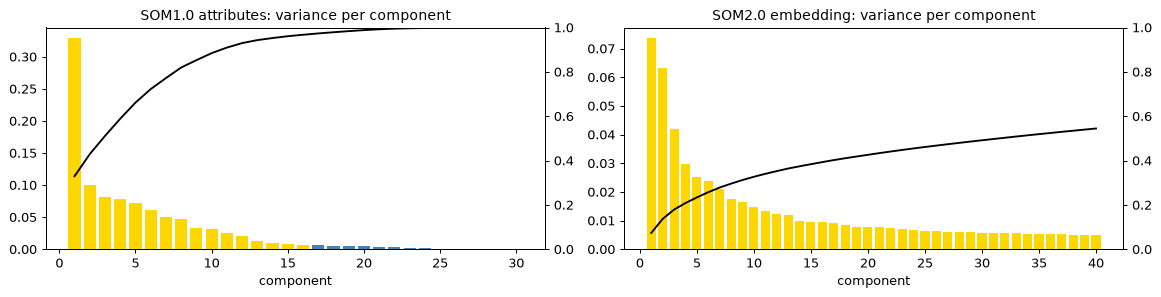

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for a, (title, v, k) in zip(ax, [("SOM1.0 attributes", pca1["var_ratio"], len(sel_idx)), ("SOM2.0 embedding", pca2["var_ratio"], k2)]):
    n = min(40, len(v)); a.bar(range(1, n + 1), v[:n], color=["gold" if i < k else "steelblue" for i in range(n)])
    a2 = a.twinx(); a2.plot(range(1, n + 1), np.cumsum(v[:n]), "k-"); a2.set_ylim(0, 1)
    a.set(title=f"{title}: variance per component", xlabel="component")
plt.tight_layout(); plt.show()

*How to read it:* the attribute PCA is steep. A few components carry most of the variance, because many
attributes measure the same thing. The embedding spectrum is much flatter, so more components are needed to
represent it. Gold bars are the components used: the selected attributes for SOM1.0 (shown against the attribute
PCs for scale), and the PCs up to 70% for SOM2.0.

## 6 · The self-organising maps
Each SOM (Kohonen map) is 64 neurons on a **hexagonal** 8 × 8 map: each neuron is a prototype vector with six
neighbours. Every zone sample is assigned to its best-matching neuron. Training pulls neighbouring neurons
together, so neighbours hold similar prototypes. The neuron colours below vary smoothly across the map, and the
numbers identify each neuron.

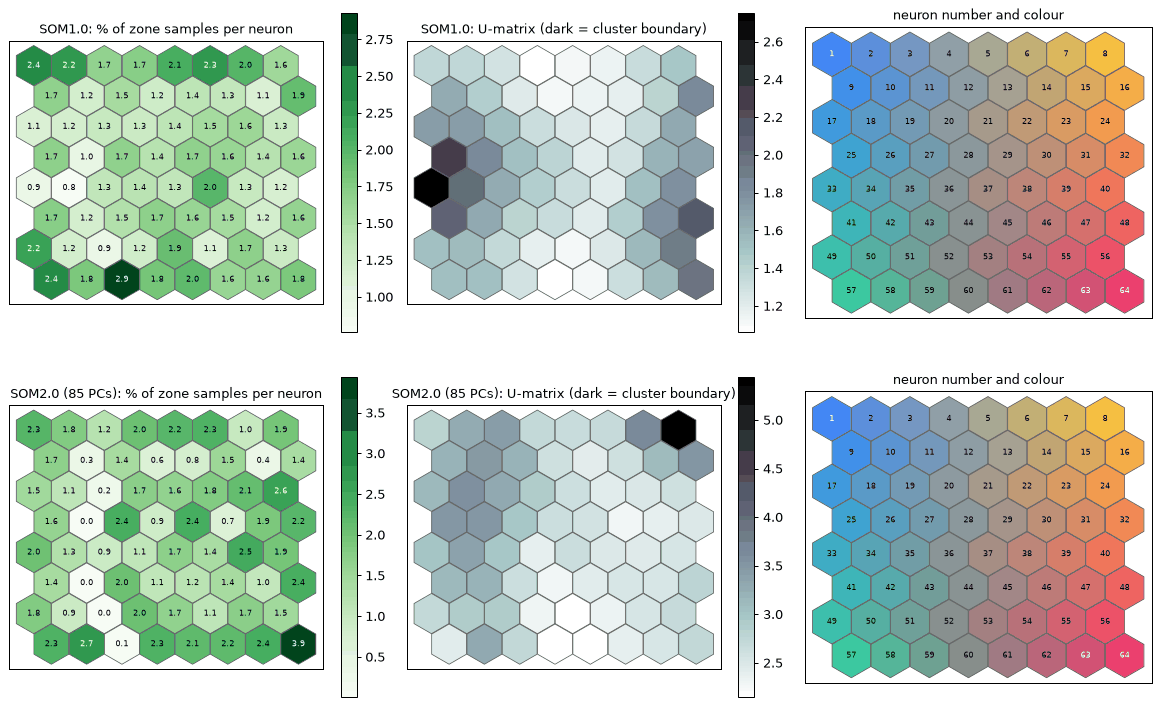

In [16]:
nodes_rgb = som2.node_colours(SOM_SHAPE)
fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for r, (name, W, b) in enumerate([("SOM1.0", W1, b1), (NAME2, W2, b2)]):
    hits = np.bincount(b, minlength=W.shape[0])
    sp.node_grid(ax[r, 0], hits / hits.sum() * 100, SOM_SHAPE, "Greens", f"{name}: % of zone samples per neuron", fmt=lambda v: f"{v:.1f}")
    sp.node_grid(ax[r, 1], sp.u_matrix(W, SOM_SHAPE), SOM_SHAPE, "bone_r", f"{name}: U-matrix (dark = cluster boundary)")
    sp.neuron_key(ax[r, 2], SOM_SHAPE, nodes_rgb, title="neuron number and colour")
plt.tight_layout(); plt.show()

*How to read it:*
- **Left, hit map:** how many samples each neuron captures. A few very full neurons and many empty ones means the
  map is poorly used.
- **Middle, U-matrix:** the distance between neighbouring prototypes. Dark ridges separate natural clusters in the
  data.
- **Right:** each neuron's number and the colour it is drawn with on the sections below.

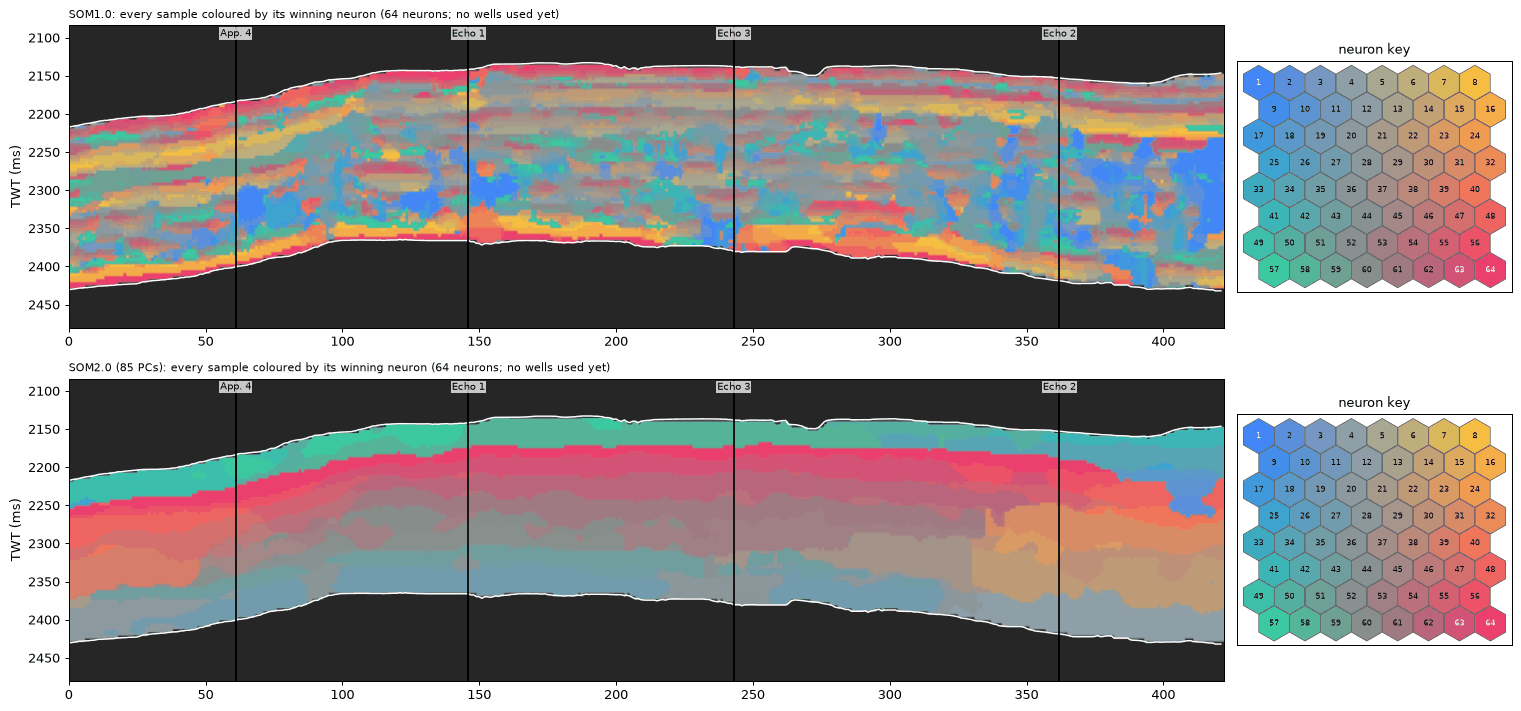

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [4.2, 1]})
for r, (name, b) in enumerate([("SOM1.0", b1), (NAME2, b2)]):
    a = ax[r, 0]
    a.imshow(sp.rgb_line(nodes_rgb[b] / 255, zone_index, path, t0, t1), aspect="auto", extent=[0, len(path), twt[t1 - 1], twt[t0]])
    sp.decorate_line(a, trange, well_pos, top, base, path)
    a.set_title(f"{name}: every sample coloured by its winning neuron (64 neurons; no wells used yet)", loc="left", fontsize=9)
    sp.neuron_key(ax[r, 1], SOM_SHAPE, nodes_rgb, title="neuron key")
plt.tight_layout(); plt.show()

*How to read it:* the raw, unsupervised result before any well information. Every sample shows the colour of
the neuron it maps to (key on the right), so each neuron can be followed through the section. Similar colours mean
neighbouring, similar neurons. SOM2.0 classes follow layers and change smoothly along them. SOM1.0 classes flicker from sample to sample,
because its features change with every wavelet loop.

## 7 · Calibrating the nodes to the wells
Every well sample falls into one node. Counting the facies seen in each node turns the 64 unsupervised classes into
facies.
- **Biggest winner:** each node takes its most frequent facies. Nodes that no calibration well visited stay
  *unknown*.
- **Probabilistic:** P(facies | node) ∝ P(node | facies) · P(facies)^0.5. P(node | facies) comes from the well
  counts, smoothed over neighbouring SOM nodes. This fills the unvisited nodes and gives a confidence.

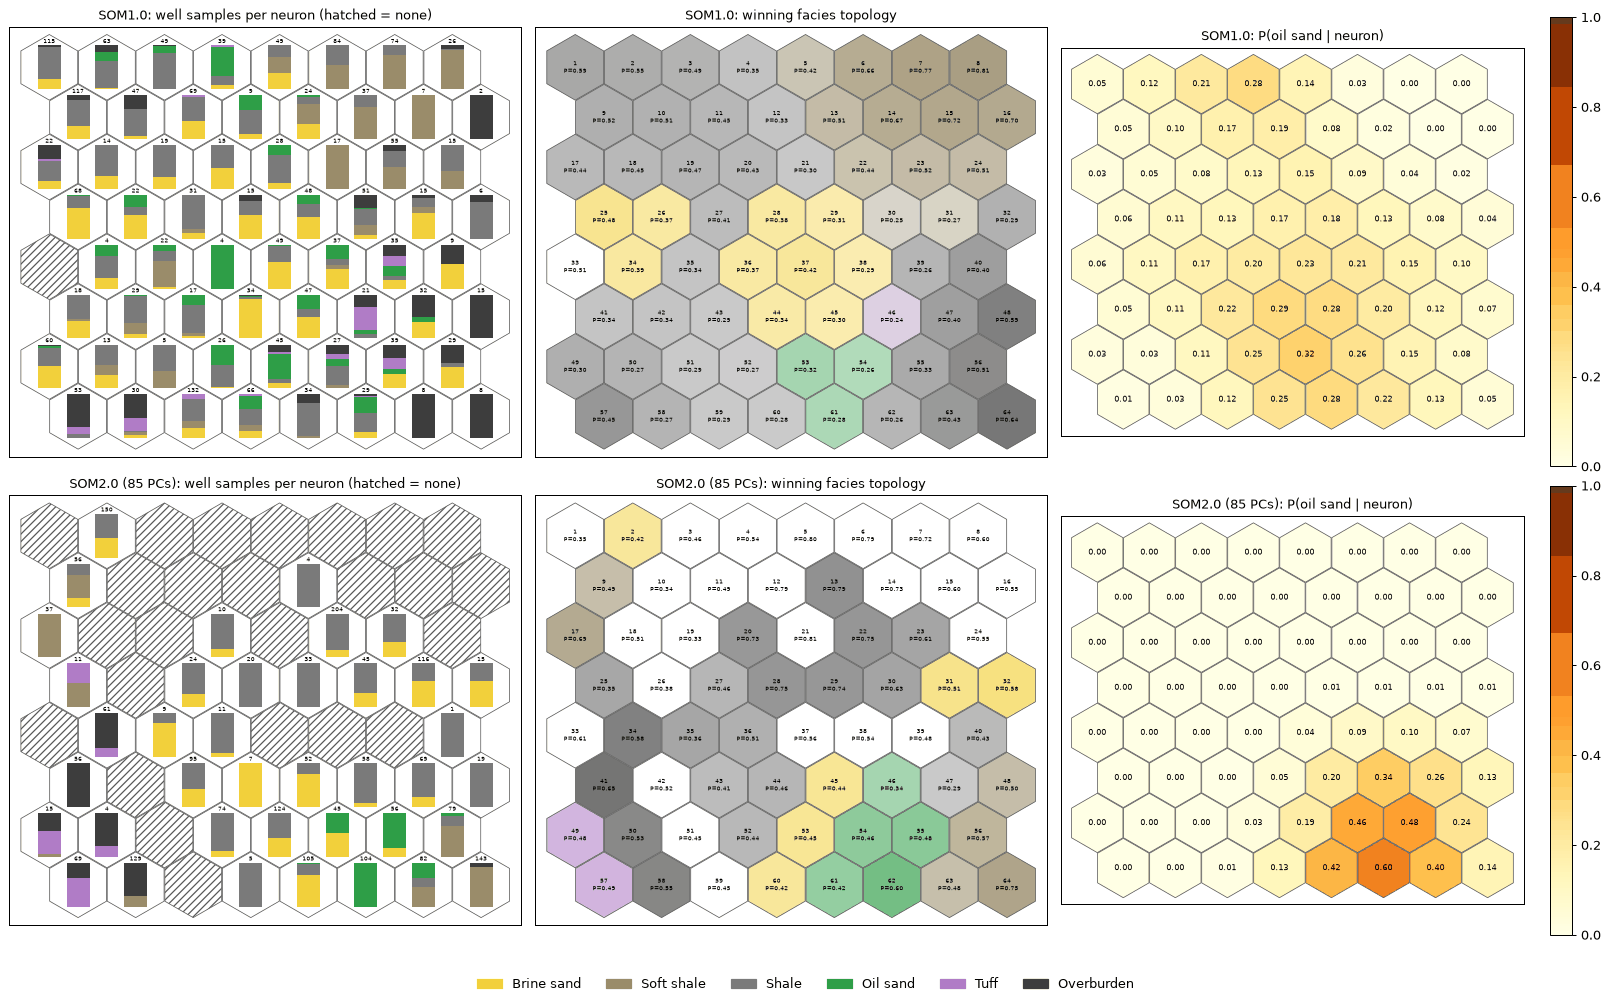

In [18]:
zi_all, fa_all = som2.calibration_samples(wells, zone_index, CAL_RADIUS)
calib = {}
fig, ax = plt.subplots(2, 3, figsize=(18, 11))
for r, (name, b) in enumerate([("SOM1.0", b1), (NAME2, b2)]):
    cnt, win, post = som2.calibrate(b[zi_all], fa_all, SOM_SHAPE[0] * SOM_SHAPE[1], n_fac, SOM_SHAPE)
    calib[name] = post
    sp.node_facies_bars(ax[r, 0], cnt, SOM_SHAPE, fac_cmap, f"{name}: well samples per neuron (hatched = none)")
    sp.facies_topology(ax[r, 1], cnt, post, SOM_SHAPE, fac_cmap, fac_names, f"{name}: winning facies topology")
    oil = code_to_k.get(4)
    if oil is not None:
        sp.node_grid(ax[r, 2], post[:, oil], SOM_SHAPE, "YlOrBr", f"{name}: P(oil sand | neuron)", vmin=0, vmax=1, fmt=lambda v: f"{v:.2f}")
sp.facies_legend(fig, fac_names, fac_cmap, y=-0.01); plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

*How to read it:*
- **Left:** the facies mix of the well samples landing in each node, with the number of samples. Hatched nodes saw
  no well data.
- **Middle, winning facies topology:** each neuron's most probable facies, with its number and probability. Paler
  means less certain. White neurons saw no well data, so their facies is inferred from their neighbours. A good map
  has each facies in one connected patch of neurons.
- **Right:** the oil-sand probability per neuron. A good map concentrates it in a compact group of neighbouring
  neurons.

## 8 · Blind test: leave one well out
For each well in turn, the nodes are calibrated with the *other* wells and the held-out well is predicted. This is
the honest test: the scored well never influenced its own prediction.

In [19]:
runs = {"SOM1.0": b1, NAME2: b2}
rows, per_well, lowo_scores = [], {}, {}
for name, b in runs.items():
    scores, pw = som2.leave_one_well_out(b, wells, zone_index, n_fac, SOM_SHAPE, CAL_RADIUS)
    per_well[name], lowo_scores[name] = pw, scores
    for m, s in scores.items():
        rows.append({"workflow": name, "calibration": m, "accuracy": s["accuracy"], "balanced accuracy": s["balanced_accuracy"],
                     "unknown": s["unknown"], **{f"recall {n}": r for n, r in zip(fac_names, s["recall"])},
                     **{f"acc {w}": pw[w][f"acc_{m}"] for w in wells}})
scores_df = pd.DataFrame(rows)
display(scores_df.style.format(precision=2, subset=scores_df.columns[2:]).hide(axis="index"))

workflow,calibration,accuracy,balanced accuracy,unknown,recall Brine sand,recall Soft shale,recall Shale,recall Oil sand,recall Tuff,recall Overburden,acc App. 3,acc App. 4,acc Echo 1,acc Echo 2,acc Echo 3
SOM1.0,winner,0.43,0.32,0.02,0.39,0.44,0.56,0.26,0.00,0.29,0.47,0.35,0.52,0.33,0.46
SOM1.0,prob,0.46,0.37,0.00,0.26,0.78,0.58,0.13,0.00,0.46,0.43,0.31,0.62,0.40,0.57
SOM2.0 (85 PCs),winner,0.38,0.40,0.41,0.07,0.58,0.35,0.78,0.00,0.61,0.31,0.20,0.52,0.40,0.48
SOM2.0 (85 PCs),prob,0.57,0.55,0.00,0.19,0.67,0.62,0.83,0.00,0.96,0.60,0.41,0.60,0.64,0.59


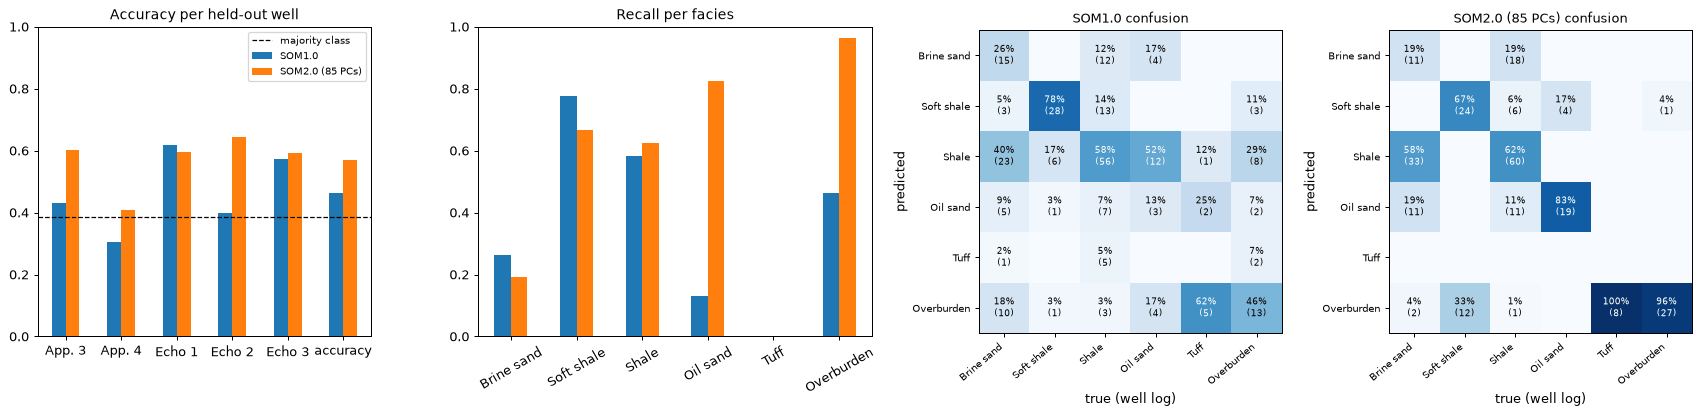

In [20]:
best2 = NAME2
prob = scores_df[scores_df.calibration == "prob"].set_index("workflow")
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), gridspec_kw={"width_ratios": [1.1, 1.3, 1, 1]})
prob[[f"acc {w}" for w in wells] + ["accuracy"]].T.rename(index=lambda s: s.replace("acc ", "")).plot.bar(ax=ax[0], rot=0)
ax[0].axhline(majority, color="k", ls="--", lw=1, label="majority class"); ax[0].set(title="Accuracy per held-out well", ylim=(0, 1)); ax[0].legend(fontsize=8)
prob[[f"recall {n}" for n in fac_names]].T.rename(index=lambda s: s.replace("recall ", "")).plot.bar(ax=ax[1], rot=30, legend=False)
ax[1].set(title="Recall per facies", ylim=(0, 1))
sp.confusion(ax[2], lowo_scores["SOM1.0"]["prob"]["confusion"], fac_names, "SOM1.0 confusion")
sp.confusion(ax[3], lowo_scores[best2]["prob"]["confusion"], fac_names, f"{best2} confusion")
plt.tight_layout(); plt.show()

*How to read it:*
- **Left:** accuracy at each held-out well and pooled. The dashed line is what you'd score by always predicting the
  most common facies.
- **Second:** recall, the share of each facies' samples that were predicted correctly.
- **Right two:** confusion matrices. Columns are the true facies, rows the predicted one, and each column sums to
  100%. A strong diagonal means facies are identified correctly. Off-diagonal cells show which facies get confused.

## 9 · Results at the wells and away from them

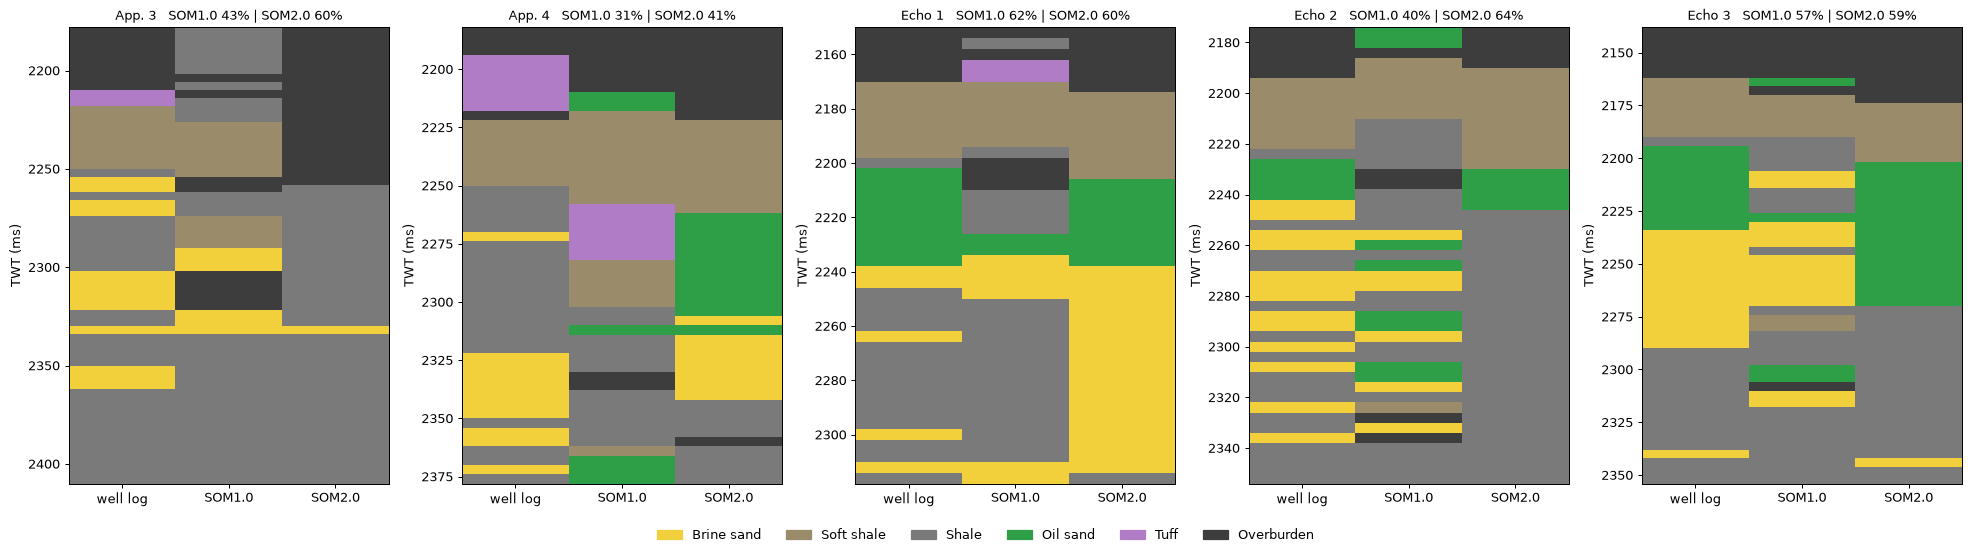

In [21]:
fig, axes = plt.subplots(1, len(wells), figsize=(4.4 * len(wells), 6.2))
for ax, w in zip(np.atleast_1d(axes), wells):
    t = twt[per_well["SOM1.0"][w]["t_index"]]
    cols = [per_well["SOM1.0"][w]["true"], per_well["SOM1.0"][w]["prob"], per_well[best2][w]["prob"]]
    ax.imshow(np.stack(cols, 1), cmap=fac_cmap, vmin=-0.5, vmax=n_fac - 0.5, aspect="auto", interpolation="nearest",
              extent=[0, 3, t.max() + dt_ms / 2, t.min() - dt_ms / 2])
    ax.set_xticks([0.5, 1.5, 2.5], ["well log", "SOM1.0", "SOM2.0"])
    ax.set_title(f"{w}   SOM1.0 {per_well['SOM1.0'][w]['acc_prob']:.0%} | SOM2.0 {per_well[best2][w]['acc_prob']:.0%}", fontsize=10)
    ax.set_ylabel("TWT (ms)")
sp.facies_legend(fig, fac_names, fac_cmap); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

*How to read it:* the blind prediction at each well, made without that well's own data, next to its facies log.

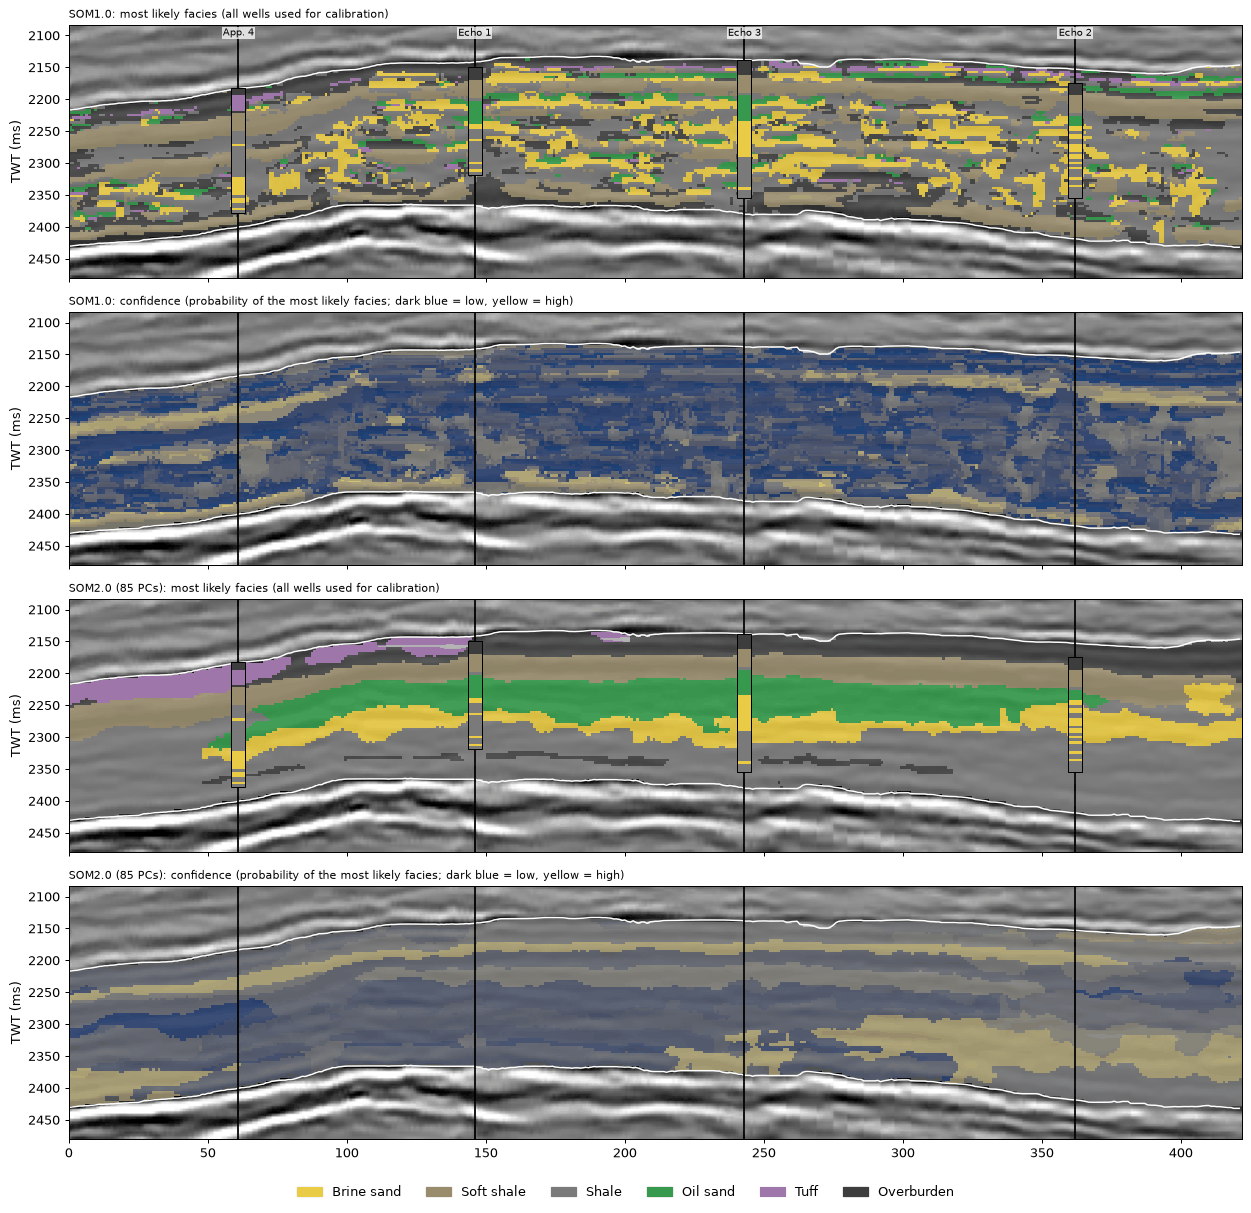

In [22]:
fig, ax = plt.subplots(4, 1, figsize=(14, 13.5), sharex=True)
for r, (name, b) in enumerate([("SOM1.0", b1), (best2, b2)]):
    post = calib[name][b]
    sp.seismic_line(ax[2 * r], cube, path, twt, t0, t1)
    sp.overlay(ax[2 * r], sp.zone_to_line(post.argmax(1).astype(float), zone_index, path, t0, t1), path, twt, t0, t1, fac_cmap, -0.5, n_fac - 0.5, 0.82)
    ax[2 * r].set_title(f"{name}: most likely facies (all wells used for calibration)", loc="left", fontsize=9)
    sp.seismic_line(ax[2 * r + 1], cube, path, twt, t0, t1)
    im = sp.overlay(ax[2 * r + 1], sp.zone_to_line(post.max(1), zone_index, path, t0, t1), path, twt, t0, t1, "cividis", 1 / n_fac, 1.0, 0.85)
    ax[2 * r + 1].set_title(f"{name}: confidence (probability of the most likely facies; dark blue = low, yellow = high)", loc="left", fontsize=9)
for a in ax:
    sp.decorate_line(a, trange, well_pos, top, base, path, label=(a is ax[0]))
for a in (ax[0], ax[2]):
    sp.well_strips(a, {n: w for n, w in wells.items() if n in well_pos}, well_pos, twt, fac_cmap, width=5, dt=dt_ms)
sp.facies_legend(fig, fac_names, fac_cmap); plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

*How to read it:* facies and confidence along the line, calibrated with all wells. The narrow outlined columns
are the well facies logs, for direct comparison. Look for geological plausibility:
continuous layers, sensible stacking, and an oil-sand body above brine sand. Also check where confidence drops,
usually at facies boundaries and away from the wells.

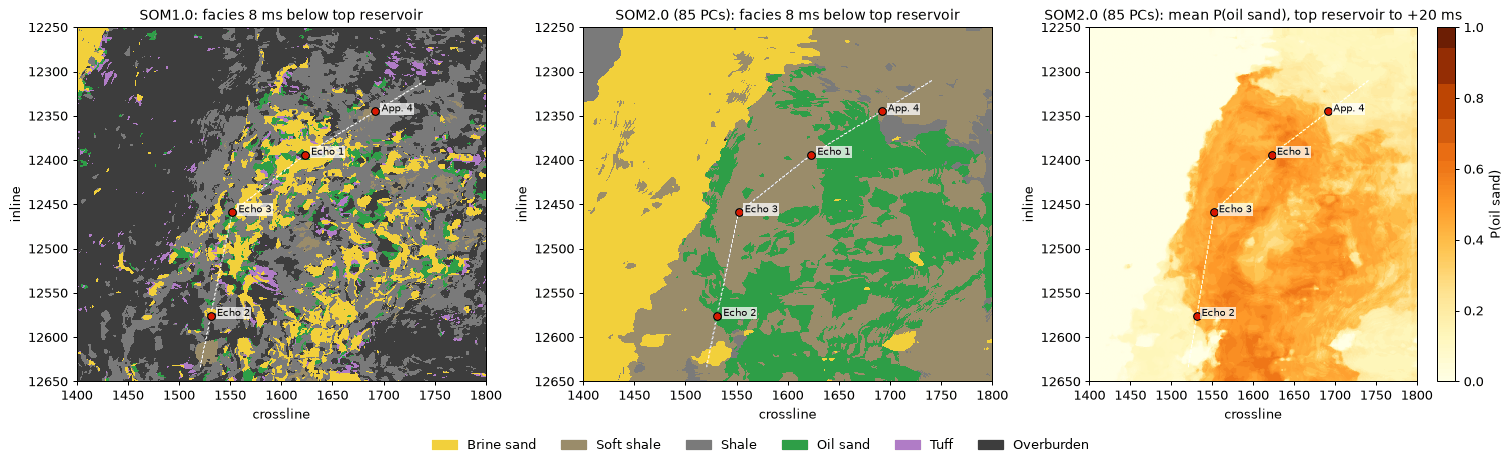

In [23]:
oil = code_to_k.get(4, 0)
rest = som2.load_horizon(MAP_HORIZON, ilines, xlines, to_ilxl)
offset = MAP_OFFSET_MS
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
ext = [xlines[0], xlines[-1], ilines[-1], ilines[0]]
for a, (name, b) in zip(ax[:2], [("SOM1.0", b1), (best2, b2)]):
    m = sp.horizon_slice(calib[name][b].argmax(1).astype(float), zone_index, rest, offset, twt)
    a.imshow(m, cmap=fac_cmap, vmin=-0.5, vmax=n_fac - 0.5, extent=ext, aspect="auto", interpolation="nearest")
    a.set_title(f"{name}: facies {offset:.0f} ms below top reservoir")
m = np.nanmean([sp.horizon_slice(calib[best2][b2][:, oil], zone_index, rest, o, twt) for o in np.arange(0, MAP_WINDOW_MS + 1, dt_ms)], 0)
im = ax[2].imshow(m, cmap="YlOrBr", vmin=0, vmax=1, extent=ext, aspect="auto"); plt.colorbar(im, ax=ax[2], label="P(oil sand)")
ax[2].set_title(f"{best2}: mean P(oil sand), top reservoir to +{MAP_WINDOW_MS} ms")
for a in ax:
    a.plot(xlines[path[:, 1]], ilines[path[:, 0]], "w--", lw=0.8)
    for n, w in [(n, w) for n, w in wells.items() if n in PLOT_WELLS]:
        a.plot(xlines[w[1][0]], ilines[w[0][0]], "o", color="red", mec="k"); a.text(xlines[w[1][0]] + 6, ilines[w[0][0]], n, fontsize=8, color="k", bbox=dict(fc="w", lw=0, alpha=0.75, pad=1))
    a.set(xlabel="crossline", ylabel="inline")
sp.facies_legend(fig, fac_names, fac_cmap); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

*How to read it:* map views extracted along the top-reservoir horizon (REST), a couple of samples below it
because the pick isn't perfect. Left two: the most likely facies for each workflow. Right: SOM2.0's oil-sand
probability averaged over the top of the reservoir. Look for coherent bodies with plausible shapes and edges,
rather than salt-and-pepper noise.

### Sections through the wells
Straight sections chosen to pass through (or close to) the wells. Every well within `WELL_PROJECTION_TRACES` of the
section is projected onto it, and its facies log is drawn as an outlined column, labelled with how far it was
projected. A well far from the line can legitimately disagree with the section.

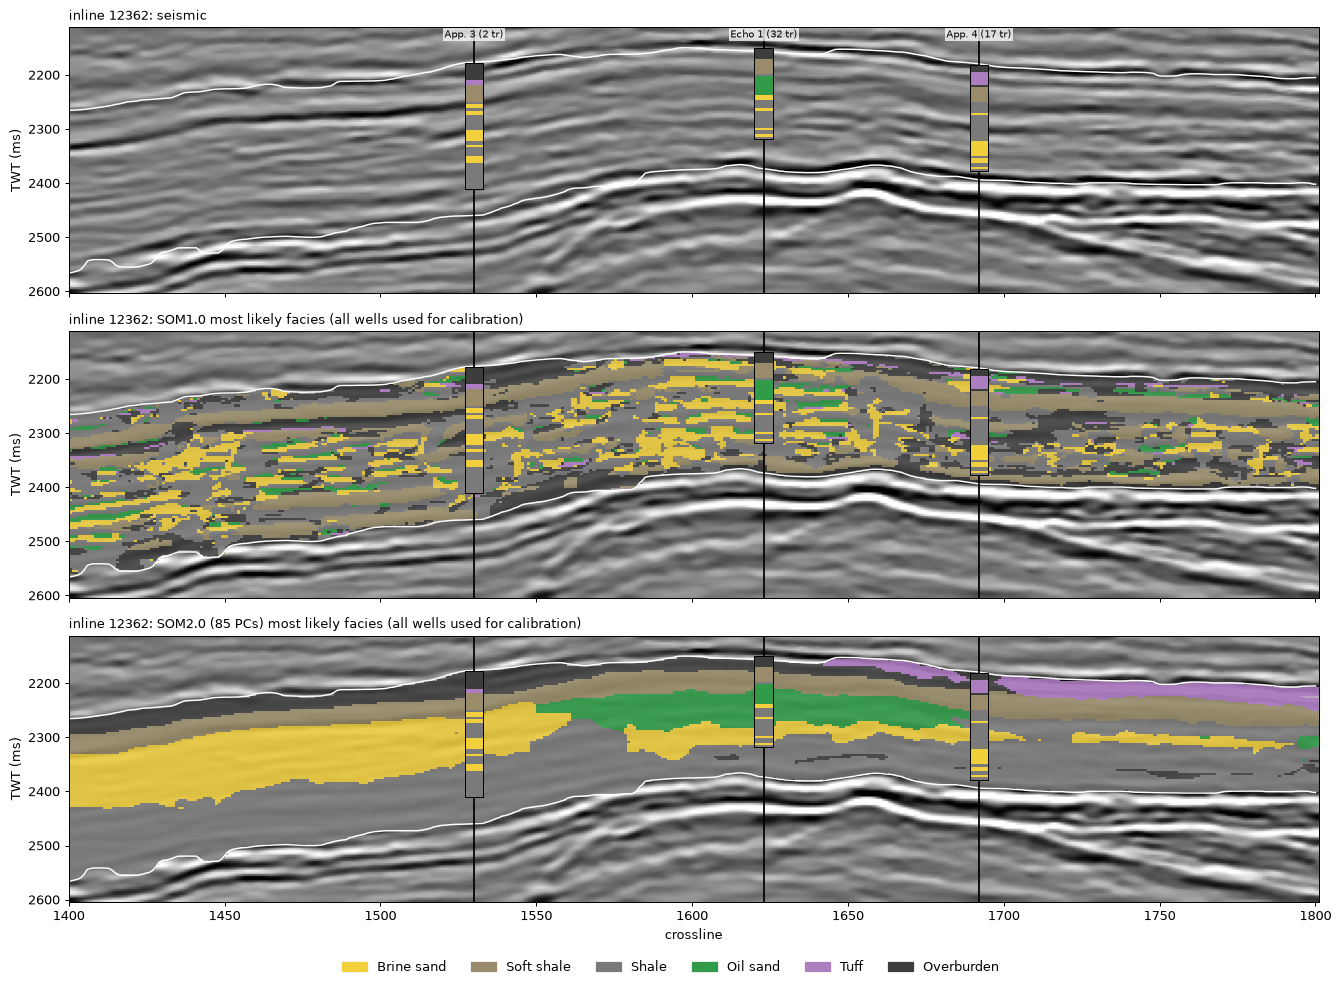

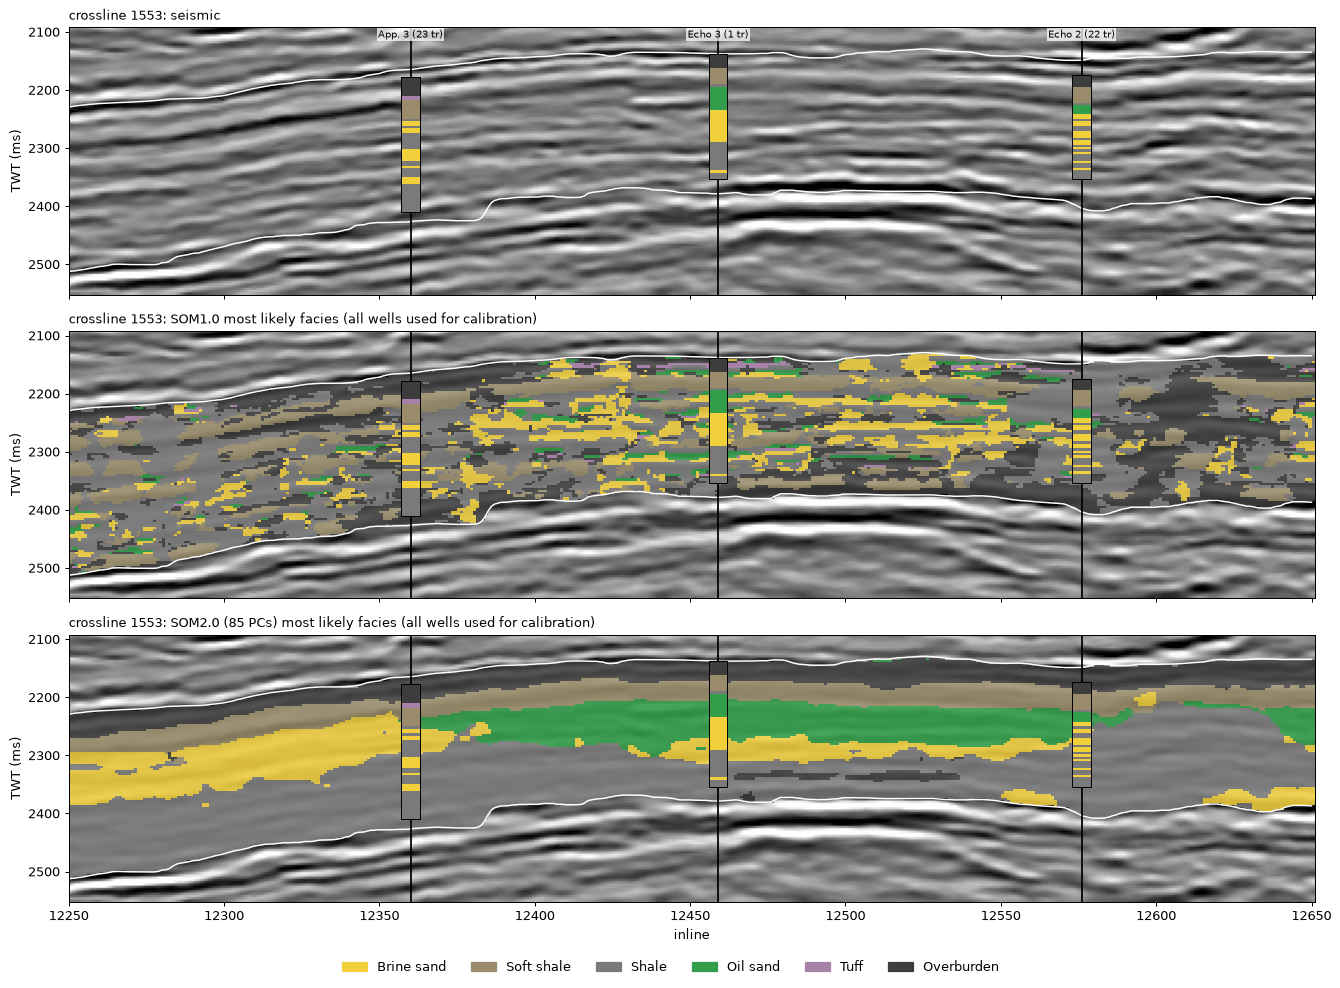

In [24]:
def straight_section(kind, number):
    if kind == "inline":
        i = int(np.searchsorted(ilines, number))
        pth = np.c_[np.full(len(xlines), i), np.arange(len(xlines))]
        axis_vals, label = xlines, "crossline"
    else:
        x = int(np.searchsorted(xlines, number))
        pth = np.c_[np.arange(len(ilines)), np.full(len(ilines), x)]
        axis_vals, label = ilines, "inline"
    near = {}
    for n, w in wells.items():
        d = abs(w[0][0] - pth[0, 0]) if kind == "inline" else abs(w[1][0] - pth[0, 1])
        if d <= WELL_PROJECTION_TRACES:
            near[n] = (int(w[1][0] if kind == "inline" else w[0][0]), int(d))
    return pth, near, axis_vals, label

for kind, number in SECTIONS:
    pth, near, axis_vals, label = straight_section(kind, number)
    s0 = int(np.searchsorted(twt, top[pth[:, 0], pth[:, 1]].min() - 40))
    s1 = int(np.searchsorted(twt, base[pth[:, 0], pth[:, 1]].max() + 40))
    rng_t = (twt[s0], twt[s1 - 1])
    pos = {f"{n} ({d} tr)": p for n, (p, d) in near.items()}
    wl = {f"{n} ({d} tr)": wells[n] for n, (p, d) in near.items()}
    fig, ax = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
    sp.seismic_line(ax[0], cube, pth, twt, s0, s1)
    ax[0].set_title(f"{kind} {number}: seismic", loc="left", fontsize=10)
    for a_, (name, b) in zip(ax[1:], [("SOM1.0", b1), (NAME2, b2)]):
        sp.seismic_line(a_, cube, pth, twt, s0, s1)
        f = calib[name][b].argmax(1).astype(float)
        sp.overlay(a_, sp.zone_to_line(f, zone_index, pth, s0, s1), pth, twt, s0, s1, fac_cmap, -0.5, n_fac - 0.5, 0.85)
        a_.set_title(f"{kind} {number}: {name} most likely facies (all wells used for calibration)", loc="left", fontsize=10)
    for a_ in ax:
        sp.decorate_line(a_, rng_t, pos, top, base, pth, label=(a_ is ax[0]))
        sp.well_strips(a_, wl, pos, twt, fac_cmap, width=6, dt=dt_ms)
    tick = np.linspace(0, len(pth) - 1, 9).astype(int)
    ax[-1].set_xticks(tick, axis_vals[tick]); ax[-1].set_xlabel(label)
    sp.facies_legend(fig, fac_names, fac_cmap); plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

*How to read it:* the same section three times: seismic, then the SOM1.0 and SOM2.0 facies calibrated with all
wells. Outlined columns are the well facies logs, projected onto the section. The number of traces each was moved
is in its label. Judge the match by the stacking of units, especially the oil sand (green) against brine sand
(yellow), rather than bed by bed: thin beds are below seismic resolution.

## 10 · Facies volumes
The deliverable of the interpretation exercise: the well-calibrated labels transferred to every sample of the zone,
written as SEG-Y with the geometry and trace headers of the input seismic. Calibration uses all wells (probabilistic).
- `<workflow>_facies.sgy`: facies code (0 outside the zone)
- `<workflow>_confidence.sgy`: probability of the most likely facies
- `<workflow>_p_oil_sand.sgy`: probability of oil sand

In [25]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
oil = code_to_k.get(4)
for name, b in [("SOM1.0", b1), ("SOM2.0", b2)]:
    post = calib[name if name == "SOM1.0" else NAME2][b]
    som2.write_zone_volume(OUTPUT_DIR / f"{name}_facies.sgy", SEISMIC, mask, np.array(codes)[post.argmax(1)].astype(np.float32))
    som2.write_zone_volume(OUTPUT_DIR / f"{name}_confidence.sgy", SEISMIC, mask, post.max(1).astype(np.float32))
    if oil is not None:
        som2.write_zone_volume(OUTPUT_DIR / f"{name}_p_oil_sand.sgy", SEISMIC, mask, post[:, oil].astype(np.float32))
print("facies codes:", {c: FACIES_NAMES.get(c, c) for c in codes}, "| 0 = outside zone ->", OUTPUT_DIR)

facies codes: {1: 'Brine sand', 2: 'Soft shale', 3: 'Shale', 4: 'Oil sand', 7: 'Tuff', 8: 'Overburden'} | 0 = outside zone -> C:\Data\Test\SEGY\som_outputs


## 11 · Caveats
- **Few wells.** Leave-one-well-out with three wells (about 140 samples) gives noisy per-facies recalls, each
  resting on 10–50 samples. Read the per-well bars as well as the totals.
- **Attribute set.** SOM1.0 uses the published formulas for standard single-trace and banded attributes, with
  PCA-based selection. Window lengths and implementation details will differ between software packages.
- **Thin beds.** Facies thinner than a few milliseconds (tuff, carbonaceous) are below seismic resolution for both
  workflows.
- **NCS model.** Each embedding vector summarises a 16 × 16-sample patch, so detail finer than about 64 ms vertically
  comes only from where the patches are placed. The 2.5D model is used here, with crop overlap 12 to suppress the
  tile-position artefact.
- **Base volume.** On this data both workflows scored better on the raw mid stack than on a structure-oriented
  filtered version. The smoothing removes texture the sample-level attributes rely on.
- **Alternatives tested.** Selecting raw embedding channels the SOM1.0 way, and SOM inputs built from cosine
  similarity (to unsupervised k-means centres, or to facies prototypes from the calibration wells), scored below
  embedding PCs. A k-nearest-neighbour classifier on the same PCs scored only slightly above the SOM, so with few
  wells the SOM step itself costs little.
- **Vertical wells and nearest-trace tie.** Deviated wells need per-sample inline/crossline positions.

In [26]:
print({k: round(v, 1) for k, v in som2.TIMINGS.items()})

{'load seismic': 4.8, 'SOM1.0 attributes': 143.1, 'SOM1.0 SOM': 3.9, 'read embedding along line': 2.9, 'ncs_load': 3.8, 'ncs_pca': 9.7, 'ncs_interp_to_seismic': 18.7, 'SOM2.0': 43.5}
